<a href="https://colab.research.google.com/github/valjeon/TP_Regresion_Softmax/blob/main/TP_softmax/TP_Softmax_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP - Clasificación Multiclase de Texto con Regresión Softmax
### Redes Neuronales / Deep Learning

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

## Objetivos
- Implementar un pipeline de preprocesamiento de texto **configurable** (stopwords, stemming, lematización, n-gramas).
- Implementar una **Regresión Softmax** (regresión logística multinomial) en PyTorch: una única capa lineal + `CrossEntropyLoss`, sin capas ocultas.
- Trackear el entrenamiento con **TensorBoard** y **MLflow**.
- Usar **Optuna** para buscar la mejor combinación de hiperparámetros de preprocesamiento *y* de entrenamiento en conjunto.

## Qué hay que completar
Los bloques marcados `# TODO` son los que tienen que completar ustedes. El resto ya está resuelto.

Esta notebook es individual/standalone: no tiene una sección de defensa grupal asociada.


## 0. Setup

In [1]:
!pip install -q mlflow optuna


Se instalan `mlflow` y `optuna` (en Colab no vienen preinstaladas):
* **MLflow** registra los parámetros, las métricas por época y el modelo entrenado de cada corrida.
* **Optuna** hace la búsqueda automática de hiperparámetros.

In [2]:
import re
import random
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42

def set_seed(seed=SEED):
    """Fija todas las semillas. Se llama antes de crear cada modelo para que cada corrida sea reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/12 13:07:06 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at /usr/local/lib/python3.13/site-packages/mlflow/assistant/skills/mlflow-trace-instrumentation/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Usando dispositivo: cpu


Se importan todas las librerías necesarias para el trabajo.

Se define una semilla (`SEED`) y la función `set_seed`, que se vuelve a llamar antes de crear cada modelo. Así cada corrida (cada trial de Optuna, cada semilla de los análisis) arranca de una inicialización conocida y los resultados se pueden reproducir. También se define el dispositivo a usar (GPU si hay, si no CPU).

In [3]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...


[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

Se descargan todo los paquetes de información que son utilizados en la etapa de preprocesamiento:
- la lista de stopwords
- wordnet que se usa para lematización
- punkt que sirve para tokenizar

## 1. Datos: 20 Newsgroups

Usamos `remove=('headers', 'footers', 'quotes')` para sacar metadata que haría el problema "demasiado fácil" (por ejemplo, el header a veces incluye el nombre del newsgroup).

In [4]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


Se carga el dataset de los 20 Newsgroups dividido en una variable de `train` y otra de `test`. No se cargan los headers, footers y quotes porque dan información acerca de las clases. Lo que queremos es clasificar en base a las palabras del documento.

Se guardan los nombres de las clases en class_names.

## 2. Preprocesamiento configurable

Vamos a armar una función de preprocesamiento con estos hiperparámetros (todos van a formar parte de la búsqueda de Optuna más adelante):

- `remove_stopwords` (`True`/`False`): sacar palabras muy frecuentes y poco informativas (`the`, `is`, `and`, ...).
- `normalization` (`"none"` / `"stem"` / `"lemmatize"`):
  - `"none"`: no se normaliza la palabra.
  - `"stem"`: **stemming** con Porter Stemmer — corta la palabra a una raíz heurística (`"running"` → `"run"`, a veces resultados no son palabras reales: `"studies"` → `"studi"`).
  - `"lemmatize"`: **lematización** con WordNet — lleva la palabra a su forma de diccionario (`"running"` → `"run"`, `"studies"` → `"study"`), más lenta pero más "correcta" lingüísticamente.

### TODO 1: completar `preprocess_text`

Pasos esperados:
1. Tokenizar el texto con `word_tokenize`.
2. Pasar todo a minúsculas y quedarse solo con tokens alfabéticos (`token.isalpha()`), para descartar números y puntuación.
3. Si `remove_stopwords` es `True`, sacar los tokens que estén en el set de stopwords.
4. Según `normalization`, aplicar `stemmer.stem(token)`, `lemmatizer.lemmatize(token)`, o dejar el token igual.
5. Devolver los tokens unidos con espacios (un string, para poder pasárselo después a `TfidfVectorizer`).

In [5]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()

def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # TODO: si remove_stopwords es True, filtrar los tokens que están en STOP_WORDS
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    # TODO: aplicar la normalización correspondiente según el valor de `normalization`
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # si normalization == "none", no se hace nada más

    return " ".join(tokens) #devuelve los tokens escritos en un solo string y no como vector

La función `preprocess_text`recibe el texto, `remove_stopwords` y `normalization`.

Primero guarda en cada posición del vector `tokens`, una palabra del texto que fue pasado a minúsculas con `lower`. Luego con `isAlpha` se conservan solo los tokens formados por caracteres alfabéticos y el resto se eliminan. De esta forma, nos deshacemos de números, signos y otros caracteres especiales que no son palabras.

Se usa la misma lógica para eliminar los stopwords si es que se pasó como parámetro de entrada. Después, según el tipo de normalización indicada en la entrada, hace stemming o lematización con cada unas de las palabras de `tokens`.

Por último, devuelve todos los tokens juntos en un solo string separados por un espacio.

In [6]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin


normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


## 3. Vectorización TF-IDF

Convertimos los textos preprocesados en vectores numéricos con `TfidfVectorizer`. Como el preprocesamiento (tokenización, stopwords, normalización) ya lo hicimos nosotros, acá solo controlamos:

- `ngram_range`: `(1,1)` solo unigramas, o `(1,2)` unigramas + bigramas (captura algo de contexto, ej. `"new york"`).
- `max_features`: tamaño máximo del vocabulario (se queda con los términos más frecuentes).
- `min_df`: un término tiene que aparecer en al menos `min_df` documentos para entrar al vocabulario (filtra términos rarísimos / errores de tipeo).

### TODO 2: completar `vectorize_data`

In [7]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    # TODO: crear un TfidfVectorizer con los parámetros recibidos y ajustarlo (fit) sobre train_texts,
    # después transformar train_texts y test_texts con ese mismo vectorizer.
    vectorizer = TfidfVectorizer(ngram_range= ngram_range, max_features= max_features, min_df= min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


La función `vectorize_data` recibe como entradas los dataset de train y de test, con qué n-gramas se quiere trabajar, el máximo de palabras con mayores frecuencias (max features) y el mínimo de frecuencia de aparición a lo largo de los documentos que tienen que tener las palabras (min df).


Se crea un `vectorizer` con las especificaciones recibidas.
Luego se le aplica al dataset de train con `fit_transform` que hace lo siguiente:
* Ve todos los documentos y arma un vocabulario.
* Calcula el IDF de cada palabra que muestra qué tan "rara" es a lo largo de todo el dataset.
* Toma el vocabulario y los valores de IDF para contar las frecuencias de las palabras (TF) en cada documento y calcular la matriz final de números.

Después se vectoriza el dataset de test pero con `transform`. Entonces, usa el vocabulario y los pesos IDF obtenidos con el dataset de train y arma la matriz.

Por último, devuelve `vectorizer` y las matrices de ambos dataset.


In [8]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])

Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


### Sobre la normalización de los vectores

`TfidfVectorizer` usa por defecto `norm='l2'`, así que cada fila de la matriz ya sale con norma euclídea 1. En la versión anterior del TP había agregado un hiperparámetro `norm_type` (`'l2'` / `'none'`) que aplicaba un `Normalizer(norm='l2')` después de la vectorización. Normalizar L2 un vector que ya tiene norma 1 no lo cambia (la operación es idempotente), así que **las dos ramas producían exactamente los mismos datos**: la diferencia de accuracy entre `'l2'` y `'none'` que aparecía en Optuna era ruido y la conclusión que saqué de eso no tenía base.

Por eso saqué `norm_type` de la búsqueda. La celda siguiente lo comprueba con el ejemplo de arriba.

In [9]:
from sklearn.preprocessing import Normalizer

_norms = np.sqrt(_Xtr.multiply(_Xtr).sum(axis=1)).A1
print("Norma L2 de cada fila que devuelve TfidfVectorizer:", np.round(_norms, 6))
_Xtr_renorm = Normalizer(norm="l2").fit_transform(_Xtr)
print("Diferencia máxima tras aplicar Normalizer(l2) encima:", abs(_Xtr - _Xtr_renorm).max())

Norma L2 de cada fila que devuelve TfidfVectorizer: [1. 1. 1.]
Diferencia máxima tras aplicar Normalizer(l2) encima: 0.0


## 4. Modelo: Regresión Softmax

La regresión softmax (regresión logística multinomial) es el modelo más simple posible para clasificación multiclase: **una sola capa lineal** que mapea el vector de entrada a un score (logit) por clase, sin ninguna no-linealidad ni capa oculta.

`CrossEntropyLoss` de PyTorch ya incluye internamente un `log_softmax` + `NLLLoss`, así que el modelo **no debe aplicar softmax en el forward** — hay que devolver los logits crudos.

### TODO 3: completar `SoftmaxRegression`

In [10]:
class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        # TODO: definir una única capa lineal de input_dim a num_classes
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        # TODO: devolver los logits (salida de self.linear), SIN aplicar softmax
        return self.linear(x)

Se define `SoftmaxRefression`

Dentro del `__init__`:
* `super().__init__()` es necesario para inicializar el módulo de PyTorch.

* Con `self.linear` se define que se va a aplicar una transformación lineal que recibe una cantidad de datos iniciales de tamaño `input_dim`  y devuelve un puntaje para cada clase que en total son `num_classes`.

En `forward`, se define que lo que se reciba va a pasar por la capa lineal self y se devuelven los resultados que son los logits.

In [11]:
# Sanity check
_dummy = torch.randn(4, 50)
_model_check = SoftmaxRegression(input_dim=50, num_classes=20)
_out = _model_check(_dummy)
assert _out is not None and _out.shape == (4, 20), "Revisá SoftmaxRegression" #si alguna de las condiciones no se cumple, se pide revisar SoftmaxRegression
print("Shape de salida OK:", _out.shape)

Shape de salida OK: torch.Size([4, 20])


## 5. Entrenamiento (ya resuelto)

Dado que los datos vectorizados entran en memoria sin problema, armamos `DataLoader`s a partir de tensores densos. Logueamos loss y accuracy (train y validación) por época a TensorBoard, y a MLflow además los hiperparámetros y el modelo final.

In [12]:
%load_ext tensorboard


In [13]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def _sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


def train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=None,
                        run_name="softmax", verbose=True):
    """Entrena `epochs` épocas. Si val_loader es None no se evalúa nada (entrenamiento final:
    el test no se mira durante el entrenamiento). Guarda además el tiempo de entrenamiento de cada época."""
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}

    for epoch in range(epochs):
        _sync()
        t0 = time.perf_counter()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        _sync()
        # tiempo de entrenamiento de la época (forward + backward + step), sin evaluación ni logging
        epoch_time = time.perf_counter() - t0
        train_loss, train_acc = running_loss / total, correct / total

        val_loss, val_acc = float("nan"), float("nan")
        if val_loader is not None:
            model.eval()
            running_loss, correct, total = 0.0, 0, 0
            with torch.no_grad():
                for xb, yb in val_loader:
                    xb, yb = xb.to(device), yb.to(device)
                    logits = model(xb)
                    loss = criterion(logits, yb)
                    running_loss += loss.item() * xb.size(0)
                    correct += (logits.argmax(dim=1) == yb).sum().item()
                    total += xb.size(0)
            val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)

        if verbose:
            msg = f"[{run_name}] Epoch {epoch+1}/{epochs} - train_loss: {train_loss:.4f} train_acc: {train_acc:.4f}"
            if val_loader is not None:
                msg += f" - val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}"
            print(msg + f" - {epoch_time:.2f}s")

        if writer is not None:
            writer.add_scalar("loss/train", train_loss, epoch)
            writer.add_scalar("accuracy/train", train_acc, epoch)
            writer.add_scalar("time/epoch_s", epoch_time, epoch)
            if val_loader is not None:
                writer.add_scalar("loss/val", val_loss, epoch)
                writer.add_scalar("accuracy/val", val_acc, epoch)
        if mlflow.active_run() is not None:
            metrics = {"train_loss": train_loss, "train_acc": train_acc, "epoch_time_s": epoch_time}
            if val_loader is not None:
                metrics.update({"val_loss": val_loss, "val_acc": val_acc})
            mlflow.log_metrics(metrics, step=epoch)

    return history

* `to_tensor_dataset` convierte los datos que le ingresan en tensores que se van a usar para los `DataLoader`s.
* `train_softmax_model` entrena el modelo por la cantidad de `epochs` que recibe y, si se le pasa un `val_loader`, lo evalúa al final de cada época.
* La función de loss es `CrossEntropyLoss`, que aplica **log-softmax** internamente.
* En `history` se guardan, por época, la loss y la accuracy de entrenamiento y validación, y **el tiempo de entrenamiento de la época** (medido con `time.perf_counter`, solo forward + backward + step, sin contar la evaluación ni el logging). Con eso se pueden comparar tiempos de convergencia entre configuraciones sin depender de la duración de los runs de MLflow.
* Si `val_loader` es `None` no se evalúa: lo uso en el entrenamiento final para no mirar el test durante el entrenamiento.

Funciones auxiliares que uso en todo el resto del notebook:
* `make_loaders` arma los `DataLoader`s con un generador con semilla, para que el orden de los batches también sea reproducible.
* `make_optimizer` crea Adam o SGD con momentum.
* `summarize_history` resume una corrida: accuracy de validación máxima y en qué época se alcanzó, la primera época en la que se llega al 99% de ese máximo (la uso como medida de **convergencia**), y los tiempos por época, total y hasta converger.
* `run_config` vectoriza una configuración y la entrena con varias semillas sobre la partición train/validación, registrando cada corrida en TensorBoard y MLflow.
* `plot_mean_std` grafica la media ± desvío entre semillas de una métrica por época.

In [14]:
def make_loaders(train_ds, val_ds, batch_size, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=g)
    val_loader = None if val_ds is None else DataLoader(val_ds, batch_size=512, shuffle=False)
    return train_loader, val_loader


def make_optimizer(name, params, lr, momentum=0.0):
    if name == "Adam":
        return optim.Adam(params, lr=lr)
    return optim.SGD(params, lr=lr, momentum=momentum)


def summarize_history(h):
    va = np.array(h["val_acc"])
    t = np.array(h["epoch_time"])
    epoch_peak = int(va.argmax()) + 1
    epoch_99 = int(np.argmax(va >= 0.99 * va.max())) + 1   # primera época con >= 99% del máximo
    return {
        "peak_val_acc": va.max(), "epoch_peak": epoch_peak, "final_val_acc": va[-1],
        "final_train_acc": h["train_acc"][-1], "epoch_99": epoch_99,
        "time_per_epoch_s": t.mean(), "time_total_s": t.sum(), "time_to_99_s": t[:epoch_99].sum(),
    }


def run_config(remove_stopwords, normalization, ngram_range, max_features, min_df,
               optimizer_name, lr, momentum, batch_size, epochs, seeds, tag, experiment_type, verbose=False):
    """Entrena una configuración con varias semillas sobre train/validación. Devuelve (histories, tamaño de vocabulario)."""
    tr_texts, val_texts = get_split_texts(remove_stopwords, normalization)
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range, max_features, min_df)
    train_ds, val_ds = to_tensor_dataset(X_tr, y_tr), to_tensor_dataset(X_val, y_val)
    histories = []
    for seed in seeds:
        set_seed(seed)
        train_loader, val_loader = make_loaders(train_ds, val_ds, batch_size, seed)
        model = SoftmaxRegression(input_dim=X_tr.shape[1], num_classes=NUM_CLASSES)
        opt = make_optimizer(optimizer_name, model.parameters(), lr, momentum)
        writer = SummaryWriter(log_dir=f"runs/{tag}_seed{seed}")
        with mlflow.start_run(run_name=f"{tag}_seed{seed}"):
            mlflow.log_params({
                "remove_stopwords": remove_stopwords, "normalization": normalization,
                "ngram_range": str(ngram_range), "max_features": max_features, "min_df": min_df,
                "optimizer_name": optimizer_name, "lr": lr, "momentum": momentum,
                "batch_size": batch_size, "epochs": epochs, "seed": seed, "experiment_type": experiment_type,
            })
            h = train_softmax_model(model, train_loader, val_loader, opt, epochs, writer=writer,
                                    run_name=f"{tag}_s{seed}", verbose=verbose)
            mlflow.log_metrics({k: float(v) for k, v in summarize_history(h).items()})
        writer.close()
        histories.append(h)
    return histories, X_tr.shape[1]


def plot_mean_std(ax, histories, key, label=None, **kw):
    arr = np.array([h[key] for h in histories])
    x = np.arange(1, arr.shape[1] + 1)
    m, s = arr.mean(axis=0), arr.std(axis=0)
    line, = ax.plot(x, m, label=label, **kw)
    ax.fill_between(x, m - s, m + s, alpha=0.2, color=line.get_color())
    return line


def summary_table(groups):
    """groups: dict etiqueta -> lista de histories (una por semilla). Devuelve media ± desvío por etiqueta."""
    rows = []
    for label, hs in groups.items():
        df = pd.DataFrame([summarize_history(h) for h in hs])
        row = {"config": label, "n_seeds": len(hs)}
        for col in ["peak_val_acc", "final_val_acc", "epoch_peak", "epoch_99",
                    "time_per_epoch_s", "time_to_99_s"]:
            row[col] = f"{df[col].mean():.4f} ± {df[col].std(ddof=0):.4f}" if "acc" in col \
                else f"{df[col].mean():.2f} ± {df[col].std(ddof=0):.2f}"
        rows.append(row)
    return pd.DataFrame(rows)

## 6. Búsqueda de hiperparámetros con Optuna

La búsqueda incluye **hiperparámetros de preprocesamiento** (`remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`) y **de entrenamiento** (optimizador, `lr`, `momentum` para SGD y `batch_size`), todos en un mismo `objective`.

**Optimización de tiempo**: como la tokenización + stopwords + normalización es lo más lento del pipeline (y solo depende de `remove_stopwords` y `normalization`, que tienen pocas combinaciones posibles), la precalculamos una sola vez para las 6 combinaciones posibles y la cacheamos. Así, cada trial de Optuna solo repite la parte rápida (vectorizar + entrenar pocas épocas).

In [15]:
print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)


Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...


  listo: (False, 'none')


  listo: (False, 'stem')


  listo: (False, 'lemmatize')


  listo: (True, 'none')


  listo: (True, 'stem')


  listo: (True, 'lemmatize')


**Partición de validación fija.** Separo una sola vez un 20% estratificado del train como validación. Esa partición se usa para la búsqueda de Optuna y para **todos** los análisis de la sección 8. El test set original solo se usa una vez, en la evaluación final (sección 8), para que la estimación de la accuracy no quede contaminada por decisiones tomadas mirándolo.

In [16]:
idx_tr, idx_val = train_test_split(
    np.arange(len(newsgroups_train.data)), test_size=0.2, random_state=SEED,
    stratify=newsgroups_train.target,
)
y_tr, y_val = newsgroups_train.target[idx_tr], newsgroups_train.target[idx_val]

def get_split_texts(remove_stopwords, normalization):
    train_texts, _ = preprocessed_cache[(remove_stopwords, normalization)]
    return [train_texts[i] for i in idx_tr], [train_texts[i] for i in idx_val]

print(f"Train: {len(idx_tr)} | Validación: {len(idx_val)} | Test (solo para la evaluación final): {len(newsgroups_test.data)}")

Train: 9051 | Validación: 2263 | Test (solo para la evaluación final): 7532


**Rango de learning rate por optimizador.** En la versión anterior usaba el mismo rango (`1e-3` a `1e-1`) para Adam y para SGD. Con ese rango, los trials con SGD terminaban con una loss de ~2.99 ≈ ln(20) = 2.996, que es la loss de un modelo que predice las 20 clases con la misma probabilidad: es decir, **SGD prácticamente no aprendía en 5 épocas**. La razón es que los vectores TF-IDF tienen norma 1 y están repartidos en miles de dimensiones, así que cada coordenada es chica y el gradiente respecto de cada peso también. Adam compensa eso porque normaliza el paso por la magnitud del gradiente; SGD no, y necesita un `lr` varios órdenes de magnitud mayor. Por eso ahora cada optimizador tiene su propio rango (`lr_adam` y `lr_sgd`).

También subí la cantidad de trials de 15 a 30 y le puse semilla al sampler, para que la búsqueda sea reproducible.

In [17]:
N_TRIALS = 30
EPOCHS_SEARCH = 5
LR_ADAM_RANGE = (1e-4, 1e-1)
LR_SGD_RANGE = (1e-1, 1e2)

def objective(trial):
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])

    optimizer_name = trial.suggest_categorical("optimizer_name", ["Adam", "SGD"])
    if optimizer_name == "Adam":
        lr = trial.suggest_float("lr_adam", *LR_ADAM_RANGE, log=True)
        momentum = 0.0
    else:
        lr = trial.suggest_float("lr_sgd", *LR_SGD_RANGE, log=True)
        momentum = trial.suggest_float("momentum", 0.0, 0.95)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # Validación = partición fija del train (no usamos el test acá)
    tr_texts, val_texts = get_split_texts(remove_stopwords, normalization)
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)

    set_seed(SEED)
    train_loader, val_loader = make_loaders(to_tensor_dataset(X_tr, y_tr), to_tensor_dataset(X_val, y_val), batch_size)
    model = SoftmaxRegression(input_dim=X_tr.shape[1], num_classes=NUM_CLASSES)
    optimizer = make_optimizer(optimizer_name, model.parameters(), lr, momentum)

    with mlflow.start_run(run_name=f"optuna_trial_{trial.number}"):
        mlflow.log_params({**trial.params, "epochs": EPOCHS_SEARCH, "experiment_type": "optuna"})
        history = train_softmax_model(model, train_loader, val_loader, optimizer,
                                      epochs=EPOCHS_SEARCH, verbose=False)

    s = summarize_history(history)
    trial.set_user_attr("train_time_s", s["time_total_s"])
    trial.set_user_attr("time_per_epoch_s", s["time_per_epoch_s"])
    trial.set_user_attr("final_train_loss", history["train_loss"][-1])
    trial.set_user_attr("final_train_acc", history["train_acc"][-1])
    trial.set_user_attr("vocab_size", X_tr.shape[1])
    print(f"trial {trial.number:2d} | {optimizer_name:4s} lr={lr:.4g} | train_loss={history['train_loss'][-1]:.3f} "
          f"| val_acc={history['val_acc'][-1]:.4f} | {s['time_total_s']:.1f}s")
    return history["val_acc"][-1]


mlflow.set_experiment("softmax_20newsgroups")
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS)

print("\nMejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", round(study.best_value, 4))

2026/11/12 13:10:29 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/12 13:10:29 INFO mlflow.store.db.utils: Updating database tables


2026/11/12 13:10:30 INFO mlflow.tracking.fluent: Experiment with name 'softmax_20newsgroups' does not exist. Creating a new experiment.


trial  0 | Adam lr=0.000355 | train_loss=2.770 | val_acc=0.5603 | 0.8s


trial  1 | SGD  lr=78.87 | train_loss=0.237 | val_acc=0.7017 | 1.1s


trial  2 | Adam lr=0.006219 | train_loss=0.567 | val_acc=0.6712 | 2.6s


... (23 outputs left out)

trial 26 | Adam lr=0.01036 | train_loss=0.770 | val_acc=0.7388 | 1.4s


trial 27 | Adam lr=0.01061 | train_loss=0.755 | val_acc=0.7388 | 1.4s


trial 28 | Adam lr=0.01328 | train_loss=0.627 | val_acc=0.7402 | 1.1s


trial 29 | Adam lr=0.04192 | train_loss=0.133 | val_acc=0.7084 | 2.5s

Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1, 'optimizer_name': 'Adam', 'lr_adam': 0.013275371418594568, 'batch_size': 128}
Mejor accuracy de validación: 0.7402


`objective`
1. Con `trial.suggest_*` se eligen los hiperparámetros del trial. El rango de `lr` depende del optimizador, y `momentum` solo se busca para SGD.
2. Se toma el texto preprocesado del cache y se separa con la partición fija de train/validación.
3. Se vectoriza con los parámetros del trial (sin normalización extra: TF-IDF ya devuelve vectores con norma L2 = 1).
4. Se fija la semilla, se crea el modelo y el optimizador y se entrena 5 épocas.
5. Cada trial queda registrado en MLflow, y en `user_attrs` del trial se guardan el tiempo de entrenamiento, la loss y la accuracy finales de train y el tamaño del vocabulario, para analizarlos después.

**Optuna Study**: se crea un estudio con el sampler TPE (con semilla) que maximiza la accuracy de validación de la última época, y se corren 30 trials. Los primeros trials de TPE son aleatorios (exploración) y después propone combinaciones cerca de las que mejor funcionaron. No prueba todas las combinaciones: el espacio tiene miles.

## 6.1. Análisis de los trials de Optuna

En vez de quedarme solo con la mejor configuración, miro todos los trials para ver qué hiperparámetros influyeron y cómo.

In [18]:
df_trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
df_trials.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in df_trials.columns]
df_trials = df_trials.rename(columns={"value": "val_acc"})
df_trials["lr"] = df_trials["lr_adam"].fillna(df_trials["lr_sgd"])

cols = ["number", "val_acc", "optimizer_name", "lr", "momentum", "batch_size", "remove_stopwords",
        "normalization", "ngram_range", "max_features", "min_df", "vocab_size",
        "final_train_loss", "final_train_acc", "train_time_s"]
pd.set_option("display.width", 250)
display(df_trials[cols].sort_values("val_acc", ascending=False).reset_index(drop=True).round(4))

,number,val_acc,optimizer_name,lr,momentum,batch_size,remove_stopwords,normalization,ngram_range,max_features,min_df,vocab_size,final_train_loss,final_train_acc,train_time_s
0,28,0.7402,Adam,0.0133,NaN,128,True,stem,1gram,10000,1,10000,0.6267,0.9316,1.1428
1,23,0.7393,Adam,0.0098,NaN,128,True,stem,1gram,10000,1,10000,0.8069,0.9206,1.1848
2,26,0.7388,Adam,0.0104,NaN,128,True,stem,1gram,10000,1,10000,0.7702,0.9227,1.4444
3,27,0.7388,Adam,0.0106,NaN,128,True,stem,1gram,10000,1,10000,0.7553,0.9237,1.4321
4,15,0.7327,Adam,0.0081,NaN,64,False,stem,1gram,10000,1,10000,0.7140,0.9212,1.6533
5,24,0.7296,Adam,0.0100,NaN,64,True,lemmatize,1gram,10000,5,10000,0.5661,0.9382,1.6435
6,3,0.7221,Adam,0.0280,NaN,128,True,lemmatize,1gram,10000,2,10000,0.3150,0.9586,1.3306
7,13,0.7207,Adam,0.0087,NaN,32,True,none,1gram,10000,1,10000,0.4670,0.9451,2.5470
8,25,0.7163,Adam,0.0028,NaN,64,True,lemmatize,1gram,10000,5,10000,1.4722,0.8896,1.7929
9,12,0.7132,Adam,0.0189,NaN,32,True,none,1gram,10000,1,10000,0.2354,0.9642,2.5409


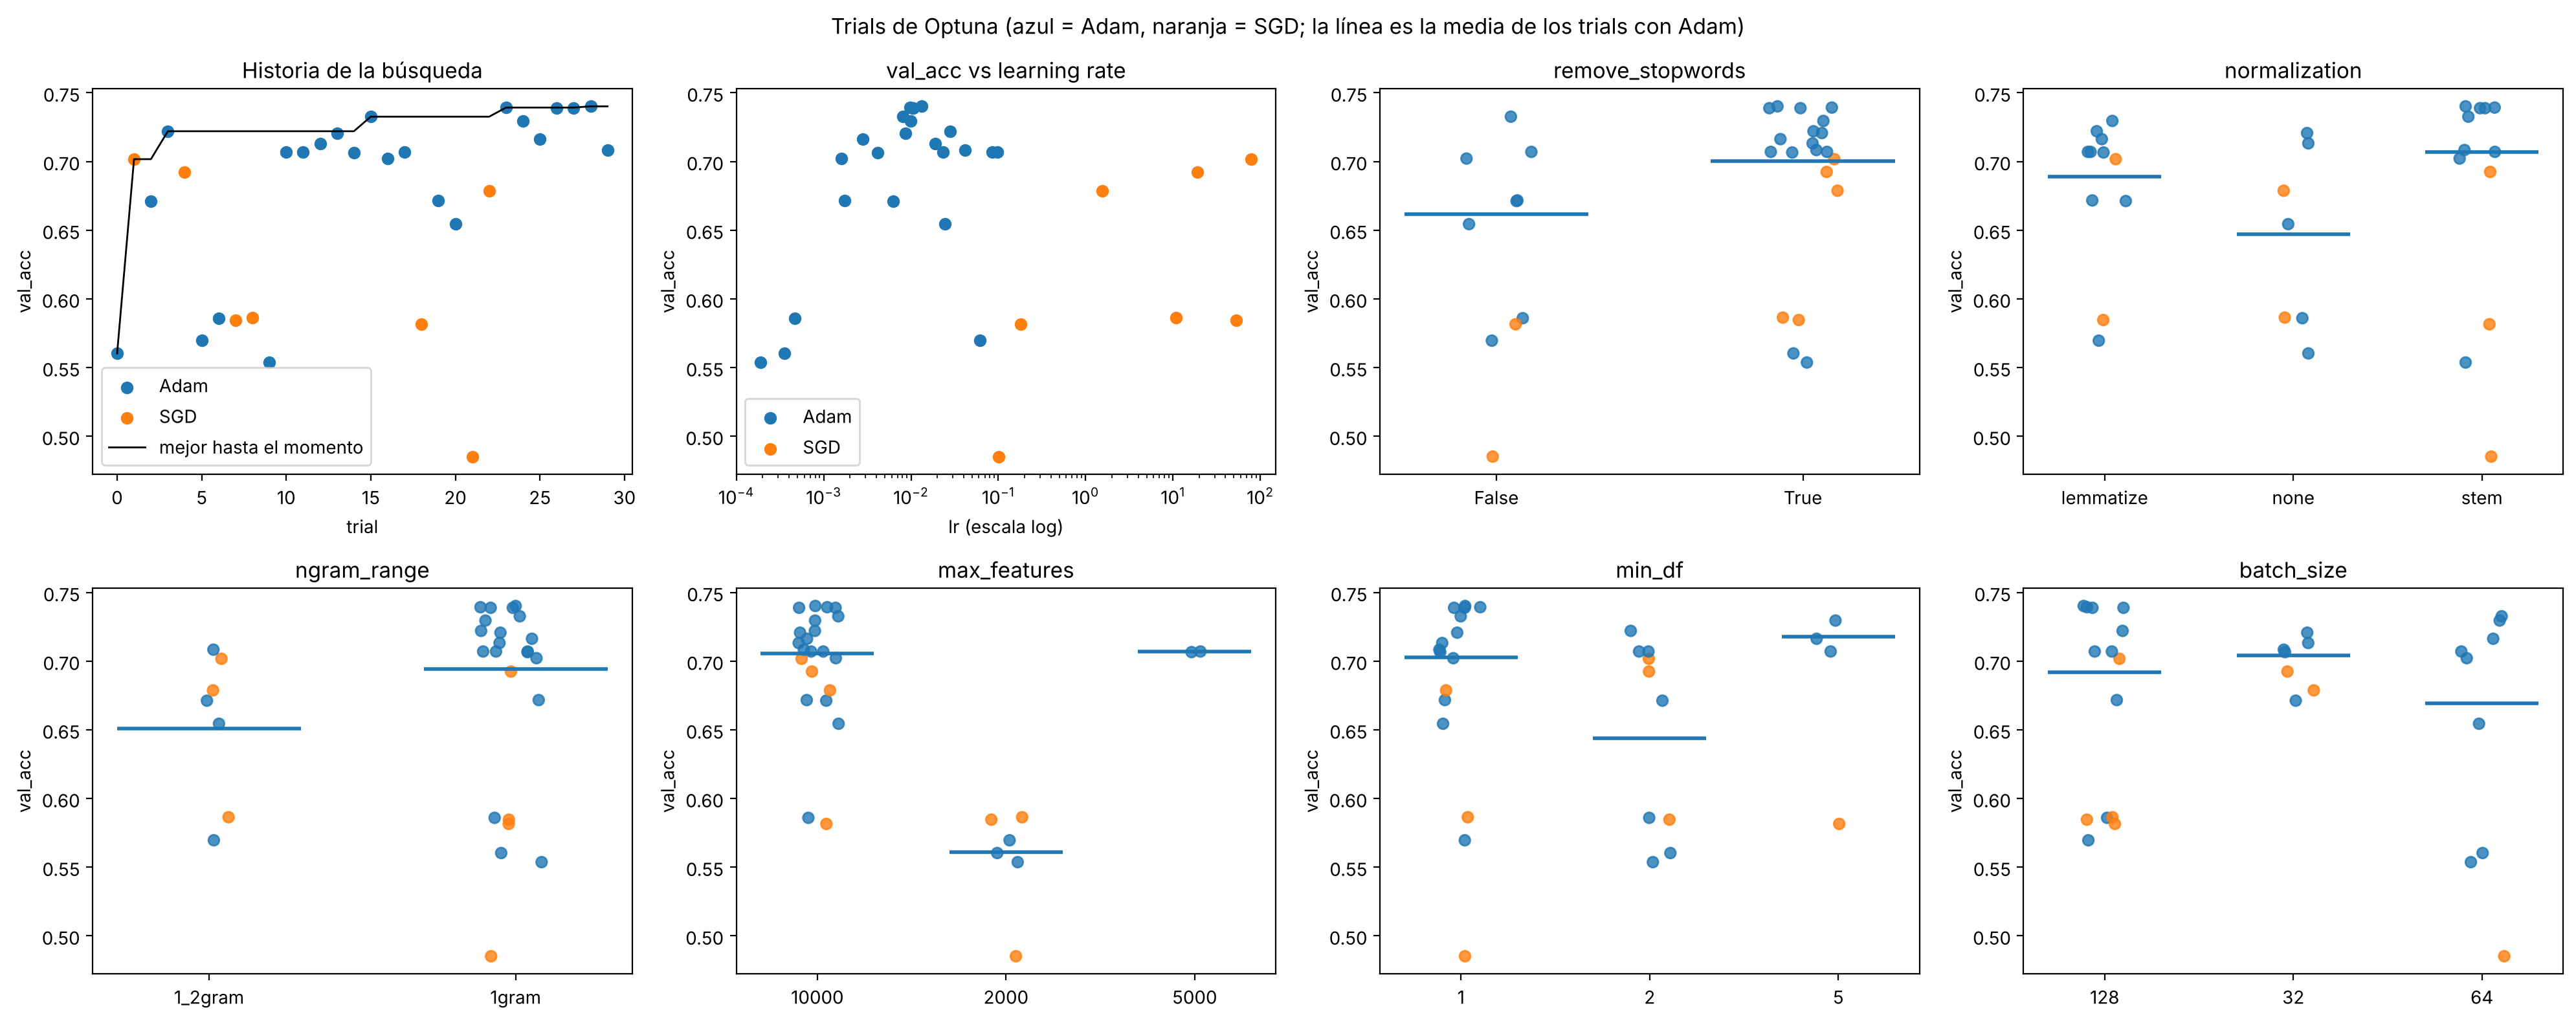

In [19]:
cats = ["remove_stopwords", "normalization", "ngram_range", "max_features", "min_df", "batch_size"]
colors = {"Adam": "tab:blue", "SGD": "tab:orange"}
rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.ravel()

# Historia de la optimización
ax = axes[0]
for opt_name, g in df_trials.groupby("optimizer_name"):
    ax.scatter(g["number"], g["val_acc"], color=colors[opt_name], label=opt_name)
ax.plot(df_trials["number"], df_trials["val_acc"].cummax(), color="k", lw=1, label="mejor hasta el momento")
ax.set_xlabel("trial"); ax.set_ylabel("val_acc"); ax.set_title("Historia de la búsqueda"); ax.legend()

# val_acc vs lr
ax = axes[1]
for opt_name, g in df_trials.groupby("optimizer_name"):
    ax.scatter(g["lr"], g["val_acc"], color=colors[opt_name], label=opt_name)
ax.set_xscale("log"); ax.set_xlabel("lr (escala log)"); ax.set_title("val_acc vs learning rate"); ax.legend()

# Hiperparámetros categóricos
for ax, p in zip(axes[2:], cats):
    levels = sorted(df_trials[p].unique(), key=str)
    for k, lev in enumerate(levels):
        g = df_trials[df_trials[p] == lev]
        x = k + rng.uniform(-0.12, 0.12, len(g))
        ax.scatter(x, g["val_acc"], c=[colors[o] for o in g["optimizer_name"]], alpha=0.8)
        adam = g[g["optimizer_name"] == "Adam"]["val_acc"]
        if len(adam):
            ax.hlines(adam.mean(), k - 0.3, k + 0.3, color="tab:blue", lw=2)
    ax.set_xticks(range(len(levels))); ax.set_xticklabels([str(l) for l in levels])
    ax.set_title(p)
for ax in axes[1:]:
    ax.set_ylabel("val_acc")
fig.suptitle("Trials de Optuna (azul = Adam, naranja = SGD; la línea es la media de los trials con Adam)")
plt.tight_layout()
plt.show()

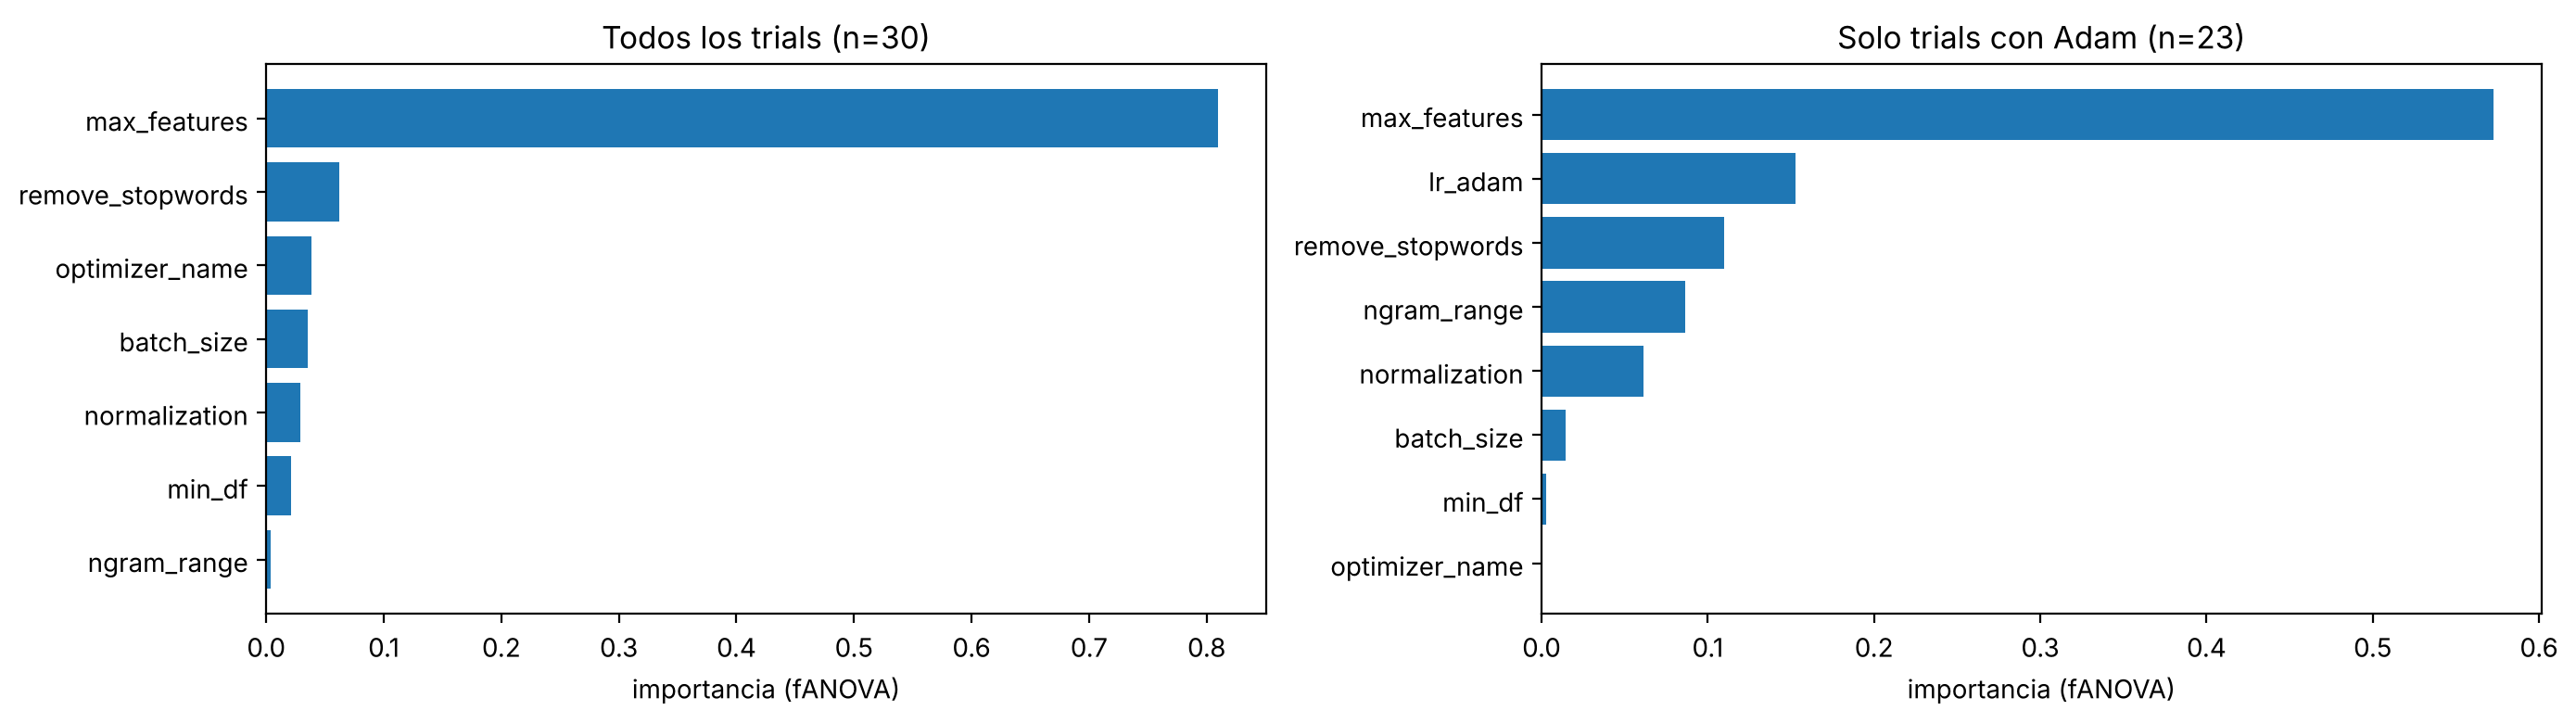

Media de val_acc por optimizador:


,count,mean,max,min
optimizer_name,,,,
Adam,23,0.6868,0.7402,0.5537
SGD,7,0.6158,0.7017,0.4852


Solo trials con Adam: media y máximo de val_acc por valor de cada hiperparámetro


,count,mean,max
remove_stopwords,,,
False,8,0.6618,0.7327
True,15,0.7001,0.7402


,count,mean,max
normalization,,,
lemmatize,9,0.6890,0.7296
none,5,0.6469,0.7207
stem,9,0.7068,0.7402


,count,mean,max
ngram_range,,,
1_2gram,4,0.6509,0.7084
1gram,19,0.6944,0.7402


,count,mean,max
max_features,,,
2000,3,0.5612,0.5696
5000,2,0.7068,0.7070
10000,18,0.7055,0.7402


,count,mean,max
min_df,,,
1,13,0.7028,0.7402
2,7,0.6439,0.7221
5,3,0.7176,0.7296


,count,mean,max
batch_size,,,
32,5,0.7040,0.7207
64,8,0.6695,0.7327
128,10,0.6920,0.7402


In [20]:
# Importancia de hiperparámetros (fANOVA). La calculo dos veces:
#  - sobre todos los trials, con los parámetros comunes a todos;
#  - solo sobre los trials con Adam, para que el lr entre en la comparación sin mezclar escalas de dos optimizadores.
evaluator = optuna.importance.FanovaImportanceEvaluator(seed=SEED)
imp_all = optuna.importance.get_param_importances(study, evaluator=evaluator)

completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
adam_study = optuna.create_study(direction="maximize")
adam_study.add_trials([t for t in completed if t.params["optimizer_name"] == "Adam"])
imp_adam = optuna.importance.get_param_importances(
    adam_study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, imp, title in [(axes[0], imp_all, f"Todos los trials (n={len(completed)})"),
                       (axes[1], imp_adam, f"Solo trials con Adam (n={len(adam_study.trials)})")]:
    names, vals = list(imp.keys())[::-1], list(imp.values())[::-1]
    ax.barh(names, vals)
    ax.set_title(title); ax.set_xlabel("importancia (fANOVA)")
plt.tight_layout(); plt.show()

print("Media de val_acc por optimizador:")
display(df_trials.groupby("optimizer_name")["val_acc"].agg(["count", "mean", "max", "min"]).round(4))
adam_df = df_trials[df_trials["optimizer_name"] == "Adam"]
print("Solo trials con Adam: media y máximo de val_acc por valor de cada hiperparámetro")
for p in cats:
    display(adam_df.groupby(p)["val_acc"].agg(["count", "mean", "max"]).round(4))

**Qué muestran los 30 trials**

* **Optimizador.** Los trials con Adam promedian 0.687 de accuracy de validación (23 trials) contra 0.616 de SGD (7 trials). Con su propio rango, SGD ahora sí aprende: los trials con `lr` entre ~1.5 y ~80 llegan a 0.68-0.70 (trials 1, 4 y 22). En cambio, los dos trials de SGD con `lr` ≈ 0.1-0.18 (18 y 21) terminan con una loss de train de 2.4-2.9, cerca de ln(20) ≈ 3.0: en 5 épocas casi no se movieron de la predicción uniforme. Es lo mismo que pasaba en la versión anterior con todo el rango `1e-3`-`1e-1`. Aun con un rango adecuado, el mejor SGD (0.702) queda por debajo del mejor Adam (0.740) con el mismo presupuesto de 5 épocas, y TPE terminó concentrando los trials en Adam.
* **Learning rate (Adam).** El gráfico `val_acc vs learning rate` tiene forma de U invertida. Con `lr` < 1e-3 la loss de train sigue en ~2.8 a las 5 épocas: no es que esos valores sean malos, sino que no llegan a converger en el presupuesto de la búsqueda (lo verifico en 8.1). Entre ~0.008 y ~0.013 están los mejores trials. Con `lr` ≥ 0.04 la loss de train baja mucho (~0.13) pero la validación queda en ~0.70-0.71: sobreajusta ya dentro de las 5 épocas.
* **`max_features`** es el hiperparámetro con más importancia según fANOVA. Todos los trials con un vocabulario de 2000 términos quedaron en ≤ 0.587, incluido el trial 5, que tenía un `lr` razonable (0.06). Con 2000 términos se pierden palabras discriminativas. Hay que tomar esa importancia con cuidado: dos de esos trials además tenían un `lr` muy bajo, así que parte del efecto se mezcla con el del `lr`, y fANOVA con 30 trials (muestreados de forma no uniforme por TPE) es solo una indicación.
* **Preprocesamiento (solo Adam).** En promedio rinden mejor `remove_stopwords=True` (0.700 contra 0.662), `stem` (0.707, contra 0.689 de `lemmatize` y 0.647 de `none`) y unigramas (0.694, contra 0.651 de `1_2gram`). Con bigramas solo hubo 4 trials; como el vocabulario está limitado a 10000 términos, agregar bigramas les quita lugar a unigramas. `min_df` y `batch_size` no muestran un patrón claro.
* **Cuidado con estas medias:** no son comparaciones controladas. TPE muestrea más cerca de las regiones que ya funcionaron, así que un valor que aparece en buenos trials suele venir acompañado de buenos valores en los demás hiperparámetros. Las comparaciones controladas (variando un solo factor, con varias semillas) están en 8.1 y 8.2.
* **El "mejor" trial es una meseta.** Los 4 mejores trials (23, 26, 27 y 28) tienen la misma configuración de preprocesamiento y Adam con `lr` entre 0.0098 y 0.0133, y están entre 0.7388 y 0.7402: diferencias de 0.1 puntos que no distinguen nada.
* **Variabilidad de la búsqueda.** En la versión anterior, dos corridas de Optuna (15 trials, sampler sin semilla) dieron "mejores" configuraciones muy distintas (una con stopwords y bigramas, la otra sin). Lo había notado pero no lo había interpretado: eso indica que, con pocos trials, la elección del mejor tiene mucha variabilidad, porque varias configuraciones quedan a menos de un punto de distancia y cuál gana depende de qué trials se sortearon. Ahora el sampler tiene semilla, lo que hace la búsqueda reproducible, pero no elimina ese problema: el ganador particular no debería sobreinterpretarse.

### Mejores hiperparámetros

Guardo la mejor configuración de la búsqueda en constantes, para usarla en el resto del notebook.

In [21]:
best = study.best_params
BEST_REMOVE_SW = best["remove_stopwords"]
BEST_NORM = best["normalization"]
BEST_NGRAM = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES = best["max_features"]
BEST_MIN_DF = best["min_df"]
BEST_OPTIMIZER_NAME = best["optimizer_name"]
BEST_LR = best["lr_adam"] if BEST_OPTIMIZER_NAME == "Adam" else best["lr_sgd"]
BEST_MOMENTUM = best.get("momentum", 0.0)  # momentum solo si el optimizador es SGD
BEST_BATCH_SIZE = best["batch_size"]

BEST_CFG = dict(remove_stopwords=BEST_REMOVE_SW, normalization=BEST_NORM, ngram_range=BEST_NGRAM,
                max_features=BEST_MAX_FEATURES, min_df=BEST_MIN_DF, optimizer_name=BEST_OPTIMIZER_NAME,
                lr=BEST_LR, momentum=BEST_MOMENTUM, batch_size=BEST_BATCH_SIZE)
SEEDS = [SEED, SEED + 1, SEED + 2]   # semillas para repetir cada experimento de análisis
for k, v in BEST_CFG.items():
    print(f"{k:18s} {v}")

remove_stopwords   True
normalization      stem
ngram_range        (1, 1)
max_features       10000
min_df             1
optimizer_name     Adam
lr                 0.013275371418594568
momentum           0.0
batch_size         128


## 6.2. Dinámica de entrenamiento

La búsqueda usa 5 épocas por trial. Antes de entrenar el modelo final, entreno la mejor configuración 30 épocas sobre train/validación con 3 semillas y miro las curvas, para ver cómo evolucionan la loss y la accuracy de train y validación (antes solo remitía a TensorBoard, que no queda embebido en el notebook).

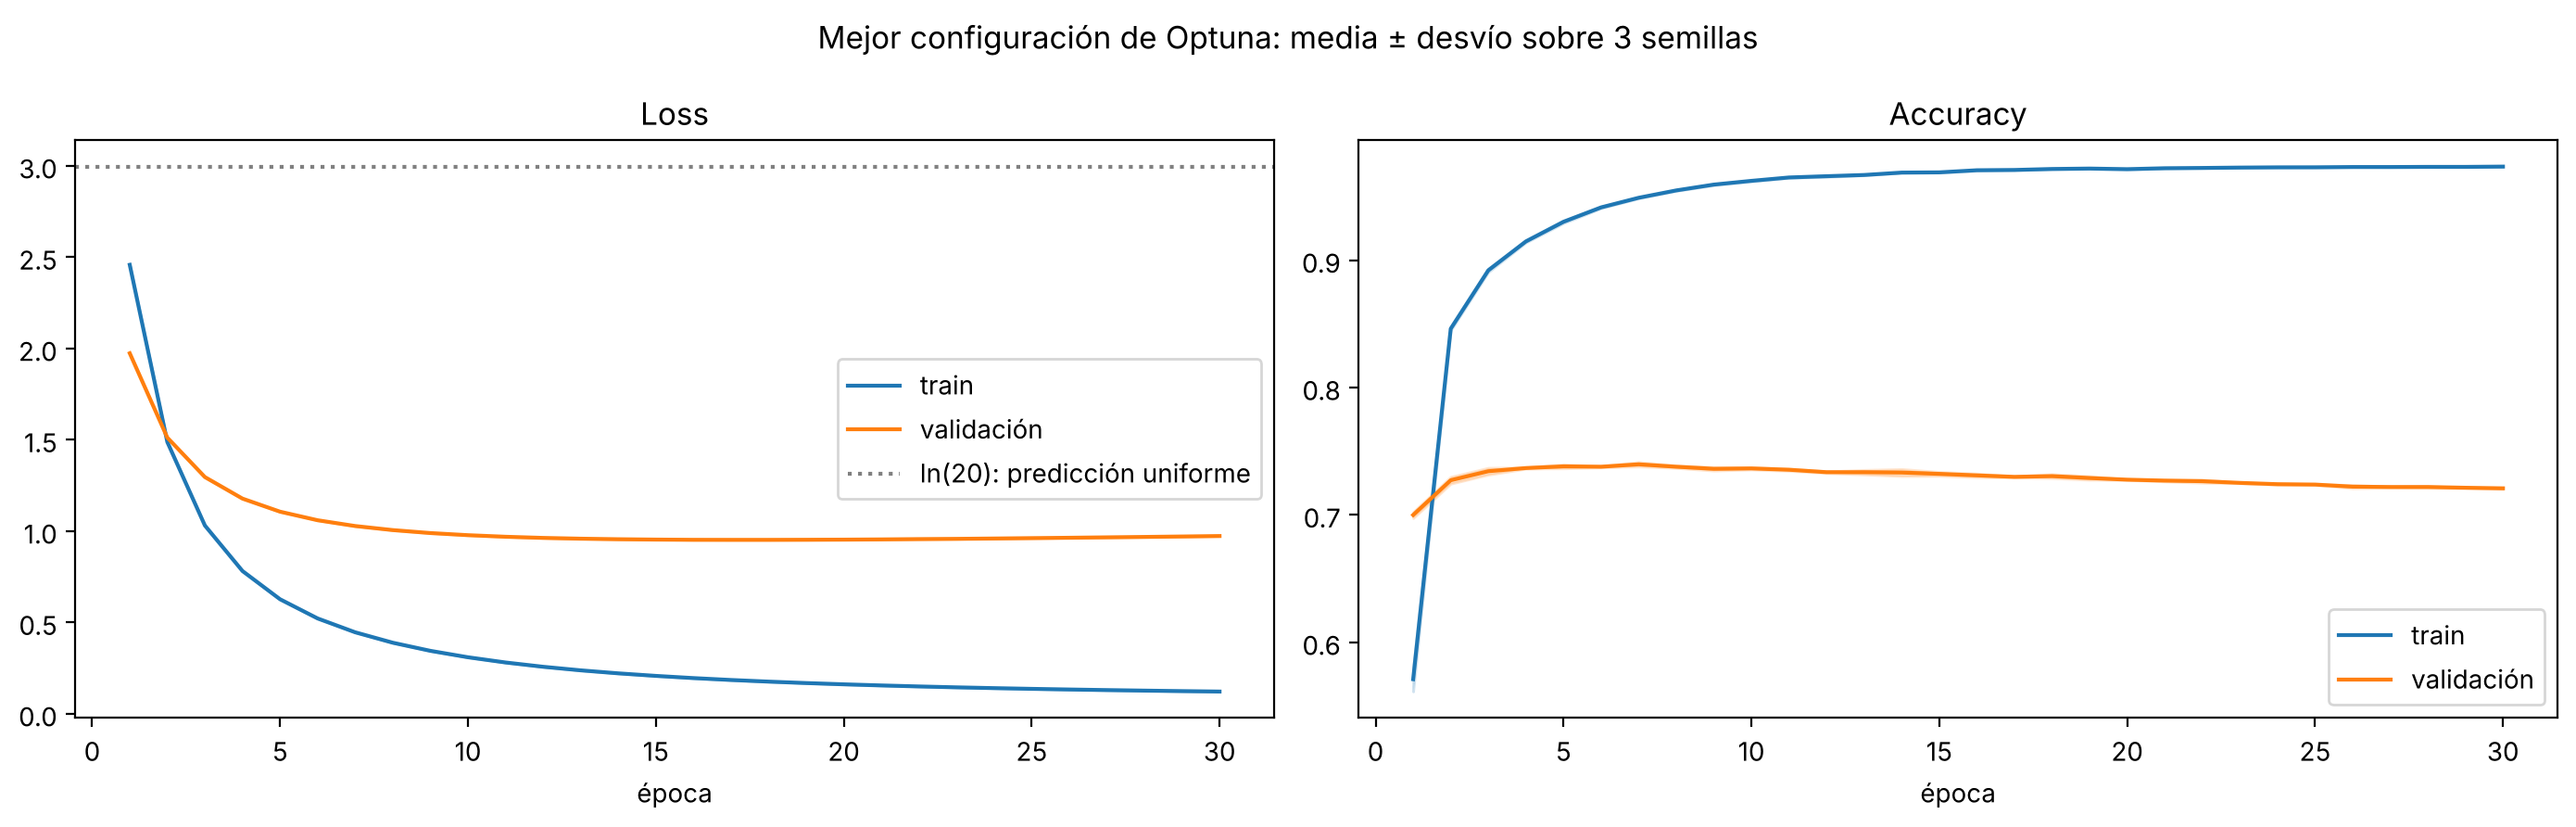

Época con mayor val_acc media: 7 (val_acc = 0.7397)
val_acc media en la época 20 (las épocas del entrenamiento final): 0.7276
Época con menor val_loss media: 17 (val_loss = 0.9515)
val_acc media en la época 30: 0.7209
Tiempo medio por época: 0.25s


,config,n_seeds,peak_val_acc,final_val_acc,epoch_peak,epoch_99,time_per_epoch_s,time_to_99_s
0,mejor config,3,0.7397 ± 0.0018,0.7209 ± 0.0006,6.00 ± 1.41,3.00 ± 0.00,0.25 ± 0.01,0.77 ± 0.06


In [22]:
EPOCHS_DYN = 30
hist_dyn, vocab_dyn = run_config(**BEST_CFG, epochs=EPOCHS_DYN, seeds=SEEDS, tag="softmax_best_dynamics",
                                 experiment_type="dynamics")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_mean_std(axes[0], hist_dyn, "train_loss", "train")
plot_mean_std(axes[0], hist_dyn, "val_loss", "validación")
axes[0].axhline(np.log(NUM_CLASSES), color="gray", ls=":", label="ln(20): predicción uniforme")
axes[0].set_title("Loss"); axes[0].set_xlabel("época"); axes[0].legend()
plot_mean_std(axes[1], hist_dyn, "train_acc", "train")
plot_mean_std(axes[1], hist_dyn, "val_acc", "validación")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("época"); axes[1].legend()
fig.suptitle("Mejor configuración de Optuna: media ± desvío sobre 3 semillas")
plt.tight_layout(); plt.show()

mean_val_acc = np.mean([h["val_acc"] for h in hist_dyn], axis=0)
mean_val_loss = np.mean([h["val_loss"] for h in hist_dyn], axis=0)
print(f"Época con mayor val_acc media: {int(mean_val_acc.argmax()) + 1} (val_acc = {mean_val_acc.max():.4f})")
print(f"val_acc media en la época 20 (las épocas del entrenamiento final): {mean_val_acc[19]:.4f}")
print(f"Época con menor val_loss media: {int(mean_val_loss.argmin()) + 1} (val_loss = {mean_val_loss.min():.4f})")
print(f"val_acc media en la época {EPOCHS_DYN}: {mean_val_acc[-1]:.4f}")
print(f"Tiempo medio por época: {np.mean([h['epoch_time'] for h in hist_dyn]):.2f}s")
display(summary_table({"mejor config": hist_dyn}))

**Dinámica de entrenamiento**

* La loss de train baja de forma monótona (a ~0.12 en la época 30) y la accuracy de train llega a ~0.97: el modelo prácticamente memoriza el train.
* La accuracy de validación sube muy rápido (llega al 99% de su máximo en la época 3), tiene su máximo en la época 7 (0.740) y después baja despacio hasta 0.721 en la época 30. La loss de validación sigue bajando hasta la época 17 y recién ahí empieza a subir. Entre las épocas 7 y 17 la accuracy baja mientras la loss todavía mejora: la loss mide las probabilidades (el modelo se vuelve más confiado en los ejemplos que ya clasificaba bien), y la accuracy solo mira el argmax.
* La brecha entre train y validación crece con las épocas: es sobreajuste (con 10000 × 20 pesos el modelo puede ajustarse a términos específicos de los documentos de train). La caída de la validación es moderada (~2 puntos entre la época 7 y la 30).
* **Épocas del modelo final.** Igual que en la versión original del TP, el modelo final se entrena **20 épocas fijas**. Según estas curvas, en la época 20 la accuracy de validación media es 0.728, ~1.2 puntos por debajo del máximo de la época 7. La loss de validación, en cambio, todavía está cerca de su mínimo (época 17). Es decir, a las 20 épocas el modelo ya empezó a sobreajustar en términos de accuracy, aunque de forma moderada. Cortar alrededor de la época 7 daría un modelo algo mejor en validación, pero la diferencia es del orden de un punto.
* Las bandas de desvío casi no se ven: entre semillas la accuracy varía ±0.002. Esa variación solo refleja la inicialización y el orden de los batches; la partición de validación es siempre la misma, así que no incluye la variabilidad que daría otro split.
* Tiempo: ~0.25 s por época en este entorno (CPU), y ~0.75 s hasta llegar al 99% del máximo.

## 7. Entrenamiento final

Usamos los mejores hiperparámetros encontrados por Optuna y entrenamos con **todo** el train set durante **20 épocas fijas**, como en la versión original del TP. Durante el entrenamiento no se evalúa sobre el test: se usa una sola vez, en la sección 8.

In [23]:
if mlflow.active_run():
    mlflow.end_run()

EPOCHS_FINAL = 20

train_texts_final, test_texts_final = preprocessed_cache[(BEST_REMOVE_SW, BEST_NORM)]
X_train_final, X_test_final, vectorizer_final = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, BEST_MAX_FEATURES, BEST_MIN_DF
)

set_seed(SEED)
train_loader_final, _ = make_loaders(to_tensor_dataset(X_train_final, newsgroups_train.target), None, BEST_BATCH_SIZE)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, newsgroups_test.target), batch_size=512, shuffle=False)

model = SoftmaxRegression(input_dim=X_train_final.shape[1], num_classes=NUM_CLASSES)
optimizer = make_optimizer(BEST_OPTIMIZER_NAME, model.parameters(), BEST_LR, BEST_MOMENTUM)

writer = SummaryWriter(log_dir="runs/softmax_final")
with mlflow.start_run(run_name="softmax_final"):
    mlflow.log_params({**{k: str(v) if isinstance(v, tuple) else v for k, v in BEST_CFG.items()},
                       "epochs": EPOCHS_FINAL, "seed": SEED, "experiment_type": "final"})
    history = train_softmax_model(model, train_loader_final, None, optimizer,
                                  epochs=EPOCHS_FINAL, writer=writer, run_name="final")
    final_train_time = sum(history["epoch_time"])
    mlflow.log_metric("train_time_s", final_train_time)

    input_example = next(iter(train_loader_final))[0][:5].numpy()
    mlflow.pytorch.log_model(model, name="model", input_example=input_example, serialization_format="pickle")
writer.close()
print(f"Tiempo total de entrenamiento: {final_train_time:.1f}s ({final_train_time / EPOCHS_FINAL:.2f}s por época)")

[final] Epoch 1/20 - train_loss: 2.3408 train_acc: 0.6003 - 0.47s


[final] Epoch 2/20 - train_loss: 1.3413 train_acc: 0.8415 - 0.31s


[final] Epoch 3/20 - train_loss: 0.9264 train_acc: 0.8840 - 0.36s


[final] Epoch 4/20 - train_loss: 0.7083 train_acc: 0.9069 - 0.36s


[final] Epoch 5/20 - train_loss: 0.5731 train_acc: 0.9248 - 0.33s


[final] Epoch 6/20 - train_loss: 0.4806 train_acc: 0.9359 - 0.37s


... (12 outputs left out)

[final] Epoch 19/20 - train_loss: 0.1631 train_acc: 0.9702 - 0.35s


2026/11/12 13:12:54 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


[final] Epoch 20/20 - train_loss: 0.1566 train_acc: 0.9706 - 0.37s


Tiempo total de entrenamiento: 6.8s (0.34s por época)


- Se usan los hiperparámetros de la búsqueda y 20 épocas fijas.
- Se vectoriza todo el train (el vocabulario y el IDF se ajustan solo con train) y se transforma el test con ese vectorizador.
- Se crea el modelo con la semilla fija y el optimizador con el learning rate de Optuna.
- Se entrena sin evaluar en el test y se registran en TensorBoard (`runs/softmax_final`) y MLflow la loss, la accuracy de train, el tiempo por época y el modelo.

## 8. Evaluación final

In [24]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader_final:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"Accuracy en test: {test_accuracy:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))


Accuracy en test: 0.6589

                          precision    recall  f1-score   support

             alt.atheism       0.51      0.49      0.50       319
           comp.graphics       0.60      0.64      0.62       389
 comp.os.ms-windows.misc       0.60      0.59      0.59       394
comp.sys.ibm.pc.hardware       0.58      0.59      0.59       392
   comp.sys.mac.hardware       0.68      0.63      0.65       385
          comp.windows.x       0.77      0.66      0.71       395
            misc.forsale       0.72      0.77      0.75       390
               rec.autos       0.46      0.76      0.57       396
         rec.motorcycles       0.73      0.68      0.71       398
      rec.sport.baseball       0.85      0.78      0.81       397
        rec.sport.hockey       0.88      0.84      0.86       399
               sci.crypt       0.78      0.70      0.74       396
         sci.electronics       0.58      0.56      0.57       393
                 sci.med       0.76      0.72    

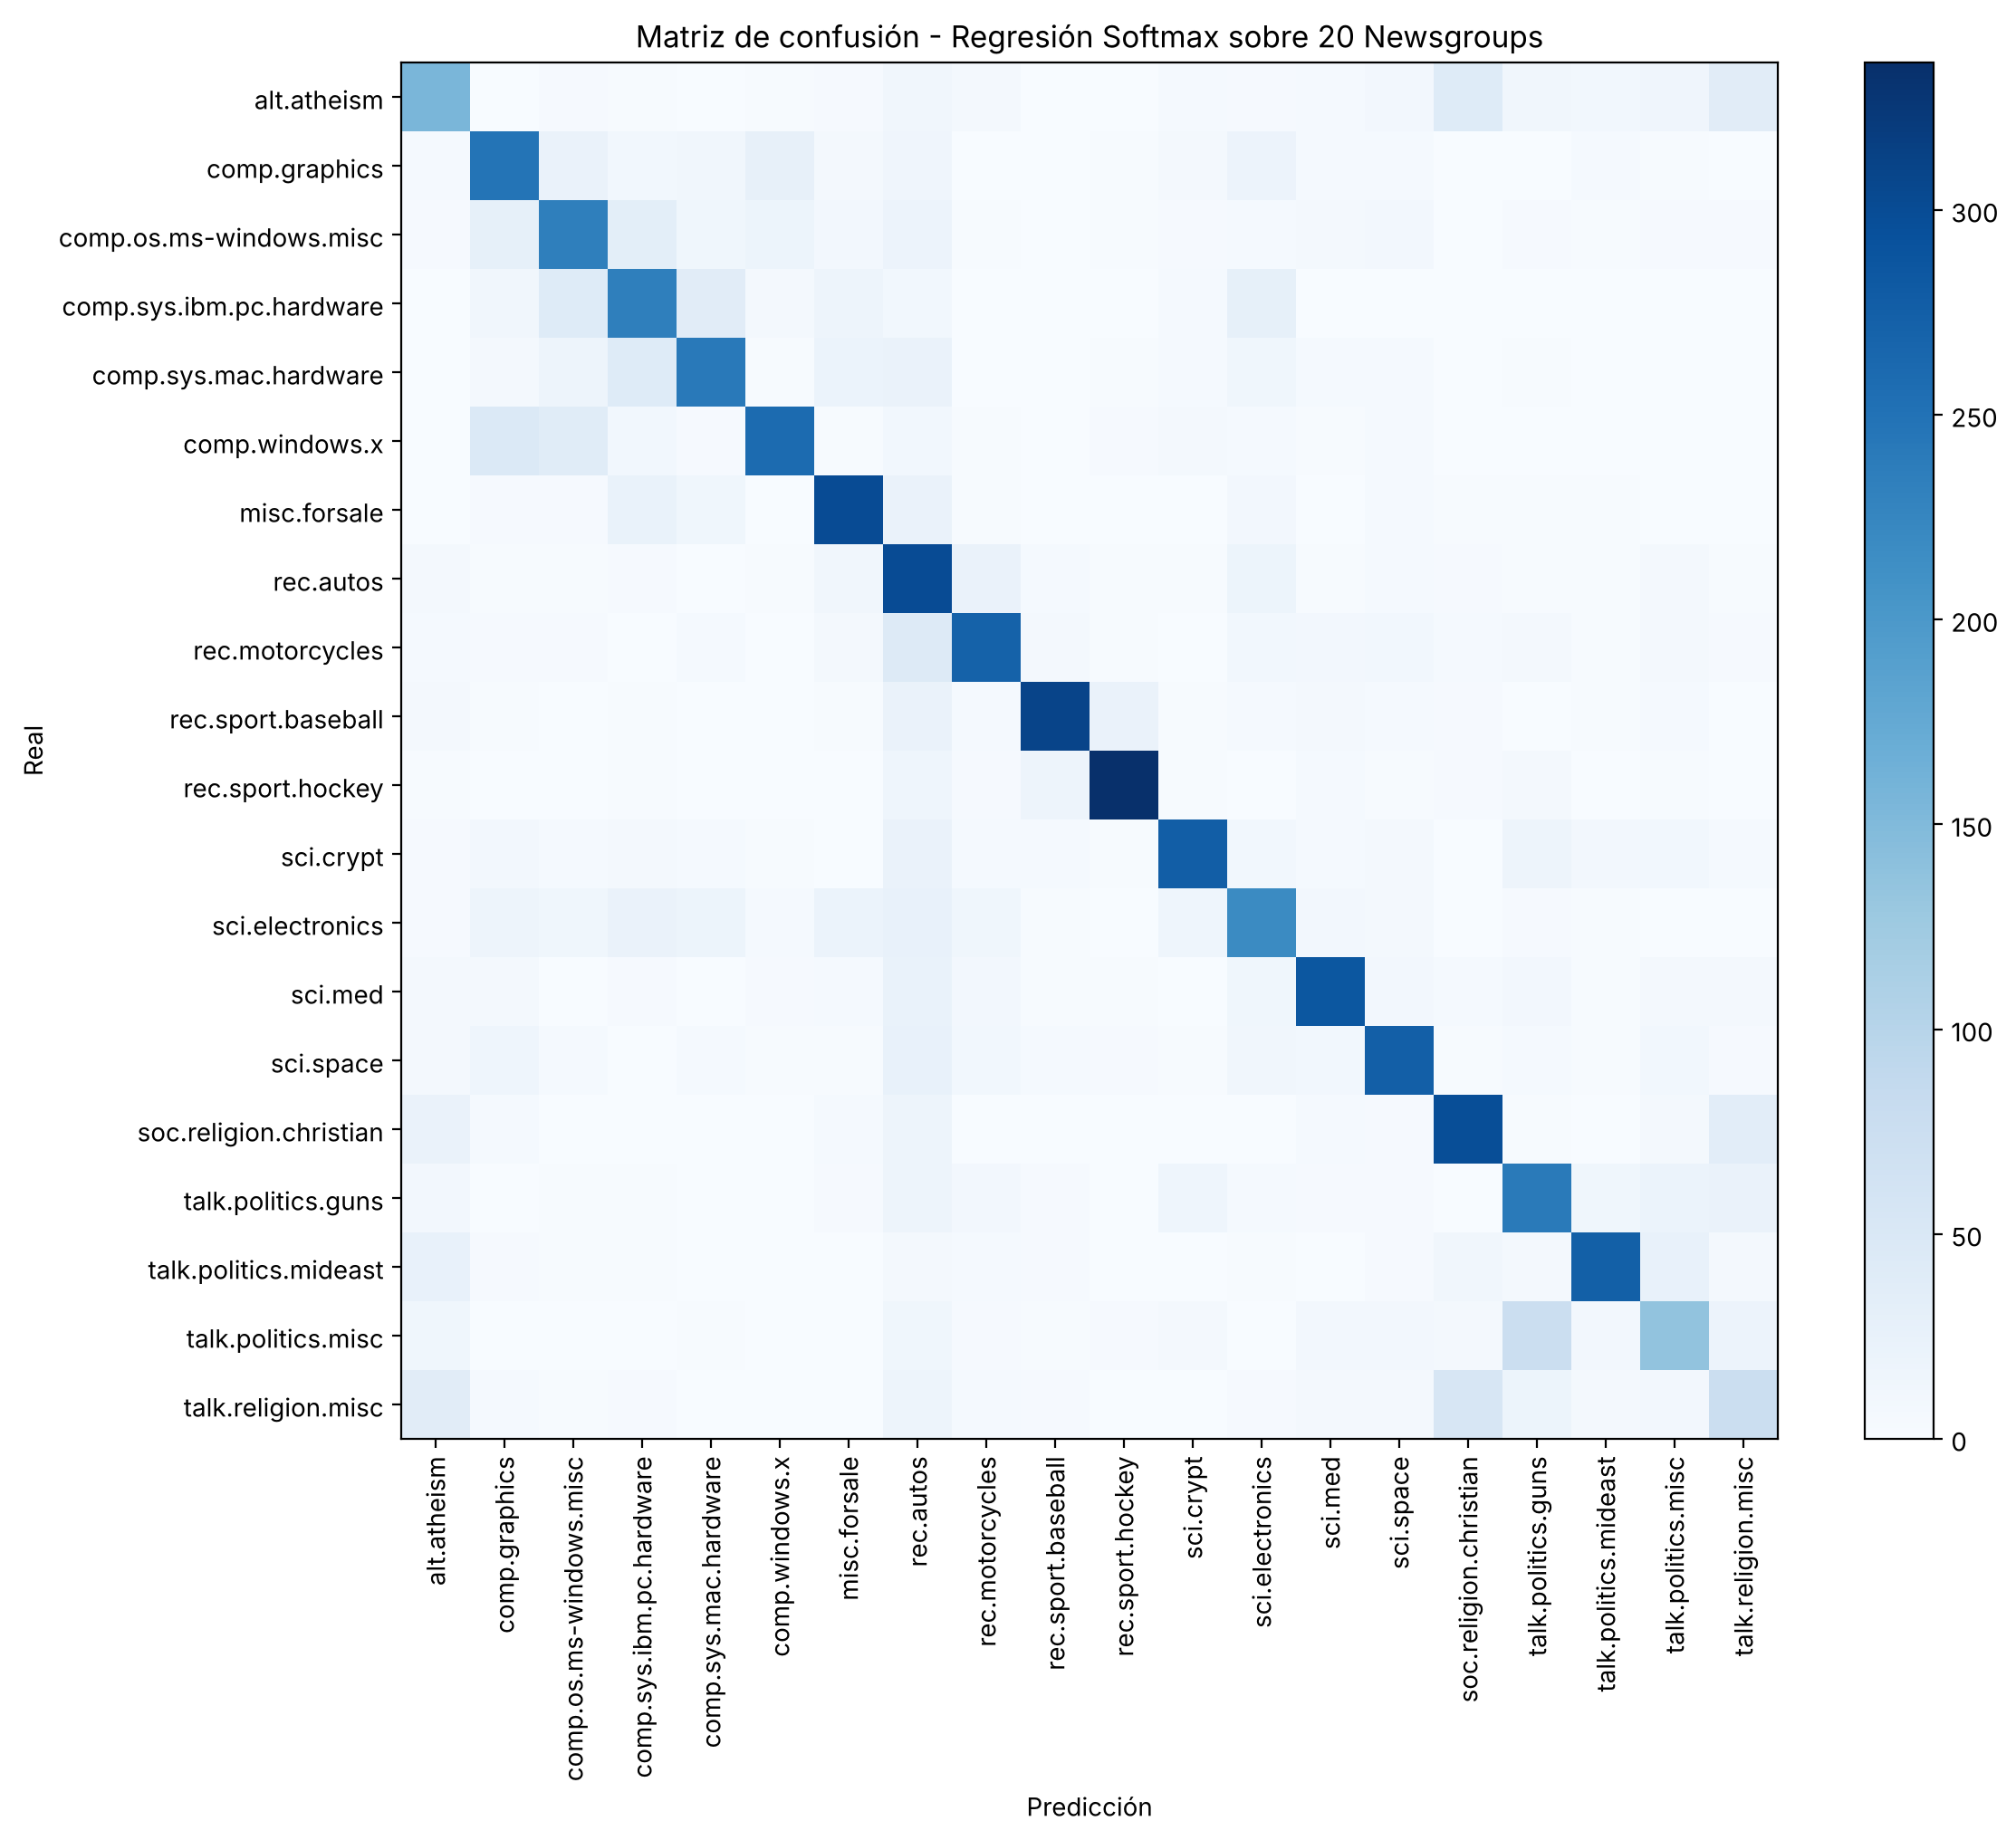

In [25]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - Regresión Softmax sobre 20 Newsgroups")
plt.tight_layout()
plt.show()


In [26]:

# Obtener las categorías que más se confunden
confused_pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j:  # Buscamos las confusiones fuera de la diagonal
            confused_pairs.append({
                'true_class': class_names[i],
                'predicted_class': class_names[j],
                'confusion_count': cm[i, j]
            })

# Ordenar los pares por el número de confusiones de mayor a menor
confused_pairs.sort(key=lambda x: x['confusion_count'], reverse=True)

print("Top 10 pares de categorías donde el modelo se confunde más:")
for i, pair in enumerate(confused_pairs[:10]):
    print(f"{i+1}. Real: '{pair['true_class']}' - Predicción: '{pair['predicted_class']}' (Confusiones: {pair['confusion_count']})")


Top 10 pares de categorías donde el modelo se confunde más:
1. Real: 'talk.politics.misc' - Predicción: 'talk.politics.guns' (Confusiones: 76)
2. Real: 'talk.religion.misc' - Predicción: 'soc.religion.christian' (Confusiones: 55)
3. Real: 'comp.windows.x' - Predicción: 'comp.graphics' (Confusiones: 47)
4. Real: 'rec.motorcycles' - Predicción: 'rec.autos' (Confusiones: 43)
5. Real: 'alt.atheism' - Predicción: 'soc.religion.christian' (Confusiones: 41)
6. Real: 'comp.sys.ibm.pc.hardware' - Predicción: 'comp.os.ms-windows.misc' (Confusiones: 41)
7. Real: 'comp.sys.mac.hardware' - Predicción: 'comp.sys.ibm.pc.hardware' (Confusiones: 41)
8. Real: 'comp.windows.x' - Predicción: 'comp.os.ms-windows.misc' (Confusiones: 39)
9. Real: 'alt.atheism' - Predicción: 'talk.religion.misc' (Confusiones: 37)
10. Real: 'comp.sys.ibm.pc.hardware' - Predicción: 'comp.sys.mac.hardware' (Confusiones: 37)


**Train, validación y test**

El modelo final termina con 0.971 de accuracy en train después de 20 épocas, la misma configuración tiene ~0.728 en validación en esa época (0.740 en su mejor época), y en test da **0.659**. Son dos brechas distintas:

* **Train → validación (~24 puntos):** es sobreajuste. Se ve en las curvas de 6.2: la loss de train sigue bajando mientras la validación se estanca y después baja levemente.
* **Validación → test (~7 puntos):** no se explica solo por sobreajuste. Hay al menos dos causas más:
  1. **Split temporal.** La versión `bydate` de 20 Newsgroups separa train y test por fecha: los mensajes de test son posteriores. Cambian los temas de discusión y el vocabulario, así que hay un corrimiento de distribución. La validación, en cambio, es una muestra aleatoria del mismo período que el train y por eso da una estimación optimista.
  2. **Sesgo de selección.** El 0.740 es el máximo de 30 trials evaluados sobre el mismo set de validación. Al elegir el mejor de muchos, parte de su ventaja es ruido a favor, así que ese valor sobreestima el rendimiento esperado aunque no haya ningún error de procedimiento.

La accuracy en test es prácticamente la misma que la de la versión entregada (0.658). Los cambios de esta versión (validación en lugar de test para los análisis, búsqueda con semilla, sin `norm_type`) no buscaban subir la accuracy, sino que la evaluación y las conclusiones sean correctas.

Las confusiones más frecuentes siguen siendo entre grupos del mismo tema: `talk.politics.misc` → `talk.politics.guns` (76), `talk.religion.misc` → `soc.religion.christian` (55), `comp.windows.x` → `comp.graphics` (47) y `alt.atheism` → `soc.religion.christian` (41). Además, varias de hardware y sistemas operativos (`ibm.pc.hardware`, `mac.hardware`, `os.ms-windows.misc`) se confunden entre sí, y `rec.motorcycles` se confunde con `rec.autos` (43): `rec.autos` tiene una precisión de solo 0.46: el modelo le asigna muchos documentos de otras clases, empezando por los de motos.

## 8.1. Análisis: efecto del learning rate

Se analiza cómo afecta el learning rate al tiempo de convergencia y al rendimiento. El resto de los hiperparámetros quedan como los de Optuna. Todas las comparaciones se hacen sobre **validación** (no sobre test) y cada learning rate se entrena con 3 semillas.

Como medida de convergencia uso la primera época en la que la accuracy de validación llega al 99% de su máximo (`epoch_99`) y el tiempo de entrenamiento hasta esa época (`time_to_99_s`).

lr=0.0001 listo


lr=0.001 listo


lr=0.01328 listo


lr=0.1 listo


,config,n_seeds,peak_val_acc,final_val_acc,epoch_peak,epoch_99,time_per_epoch_s,time_to_99_s
0,lr=0.0001,3,0.6678 ± 0.0012,0.6677 ± 0.0013,29.67 ± 0.47,23.67 ± 1.70,0.25 ± 0.01,5.83 ± 0.66
1,lr=0.001,3,0.7363 ± 0.0008,0.7362 ± 0.0010,29.67 ± 0.47,22.33 ± 0.47,0.24 ± 0.01,5.53 ± 0.09
2,lr=0.01328,3,0.7397 ± 0.0018,0.7209 ± 0.0006,6.00 ± 1.41,3.00 ± 0.00,0.25 ± 0.01,0.76 ± 0.02
3,lr=0.1,3,0.7263 ± 0.0008,0.7030 ± 0.0038,1.67 ± 0.47,1.67 ± 0.47,0.25 ± 0.01,0.47 ± 0.16


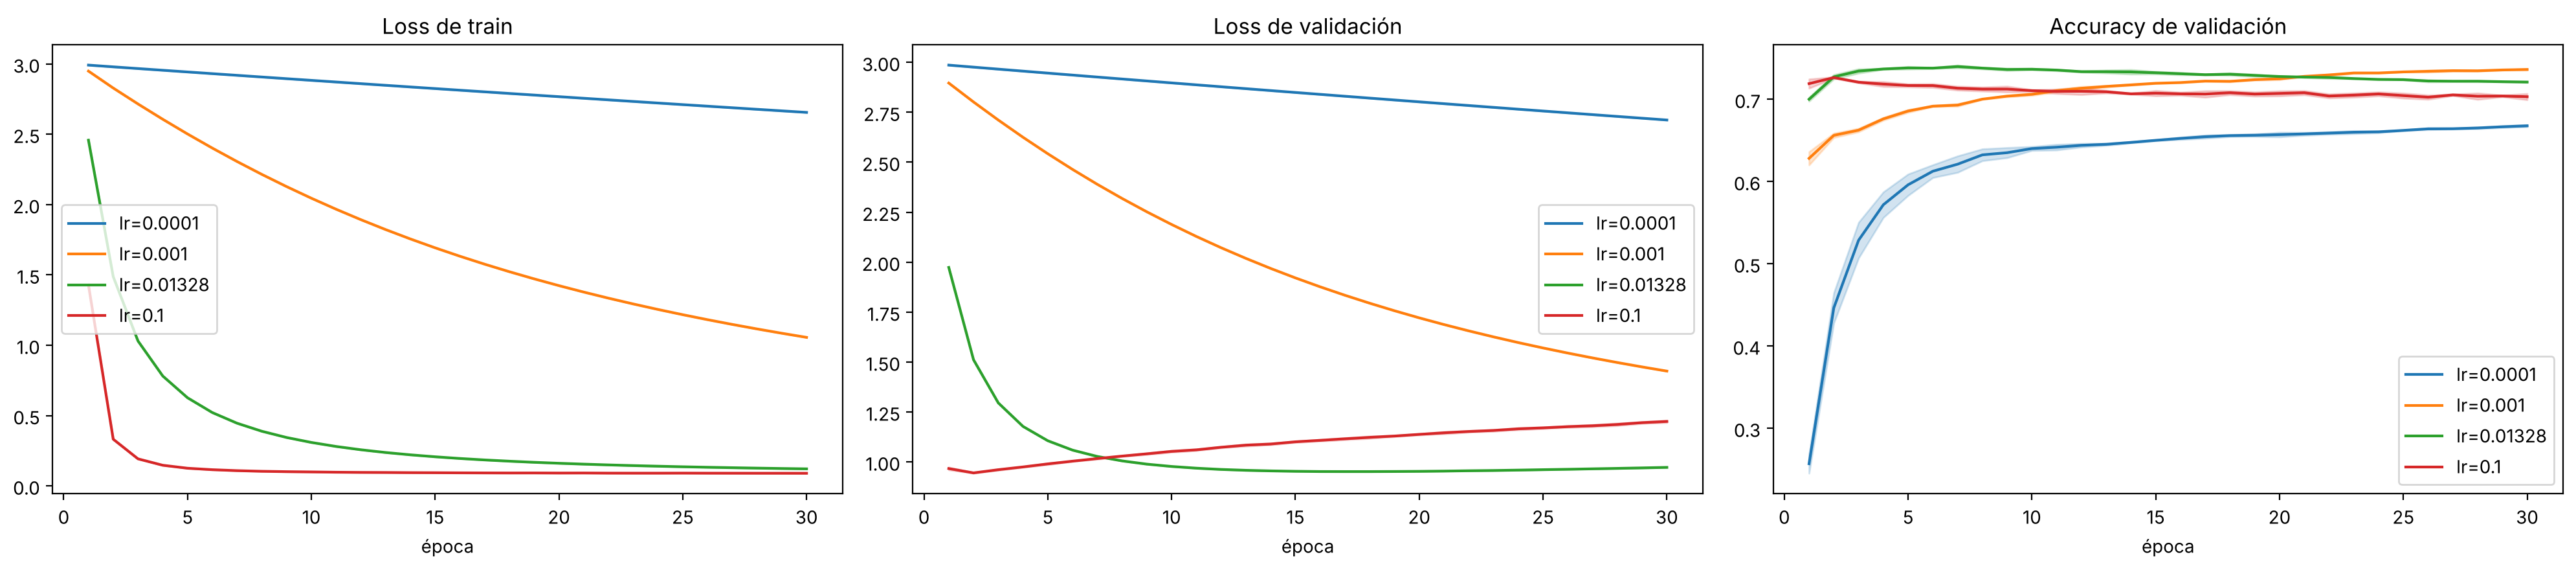

In [27]:
EPOCHS_ANALYSIS = 30
if BEST_OPTIMIZER_NAME == "Adam":
    learning_rates_to_test = sorted({1e-4, 1e-3, BEST_LR, 1e-1})
else:
    learning_rates_to_test = [BEST_LR / 100, BEST_LR / 10, BEST_LR, BEST_LR * 10]

lr_histories = {}
for current_lr in learning_rates_to_test:
    cfg = {**BEST_CFG, "lr": current_lr}
    lr_histories[f"lr={current_lr:.4g}"], _ = run_config(
        **cfg, epochs=EPOCHS_ANALYSIS, seeds=SEEDS,
        tag=f"softmax_lr_{current_lr:.4g}".replace(".", "_"), experiment_type="lr_variation")
    print(f"lr={current_lr:.4g} listo")

display(summary_table(lr_histories))

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for label, hs in lr_histories.items():
    plot_mean_std(axes[0], hs, "train_loss", label)
    plot_mean_std(axes[1], hs, "val_loss", label)
    plot_mean_std(axes[2], hs, "val_acc", label)
axes[0].set_title("Loss de train"); axes[1].set_title("Loss de validación"); axes[2].set_title("Accuracy de validación")
for ax in axes:
    ax.set_xlabel("época"); ax.legend()
plt.tight_layout(); plt.show()

Con 30 épocas no queda claro si un learning rate chico es peor o solo más lento. Para separar las dos cosas, entreno el menor learning rate durante muchas más épocas (una semilla) y lo comparo con el máximo que alcanza el learning rate de Optuna.

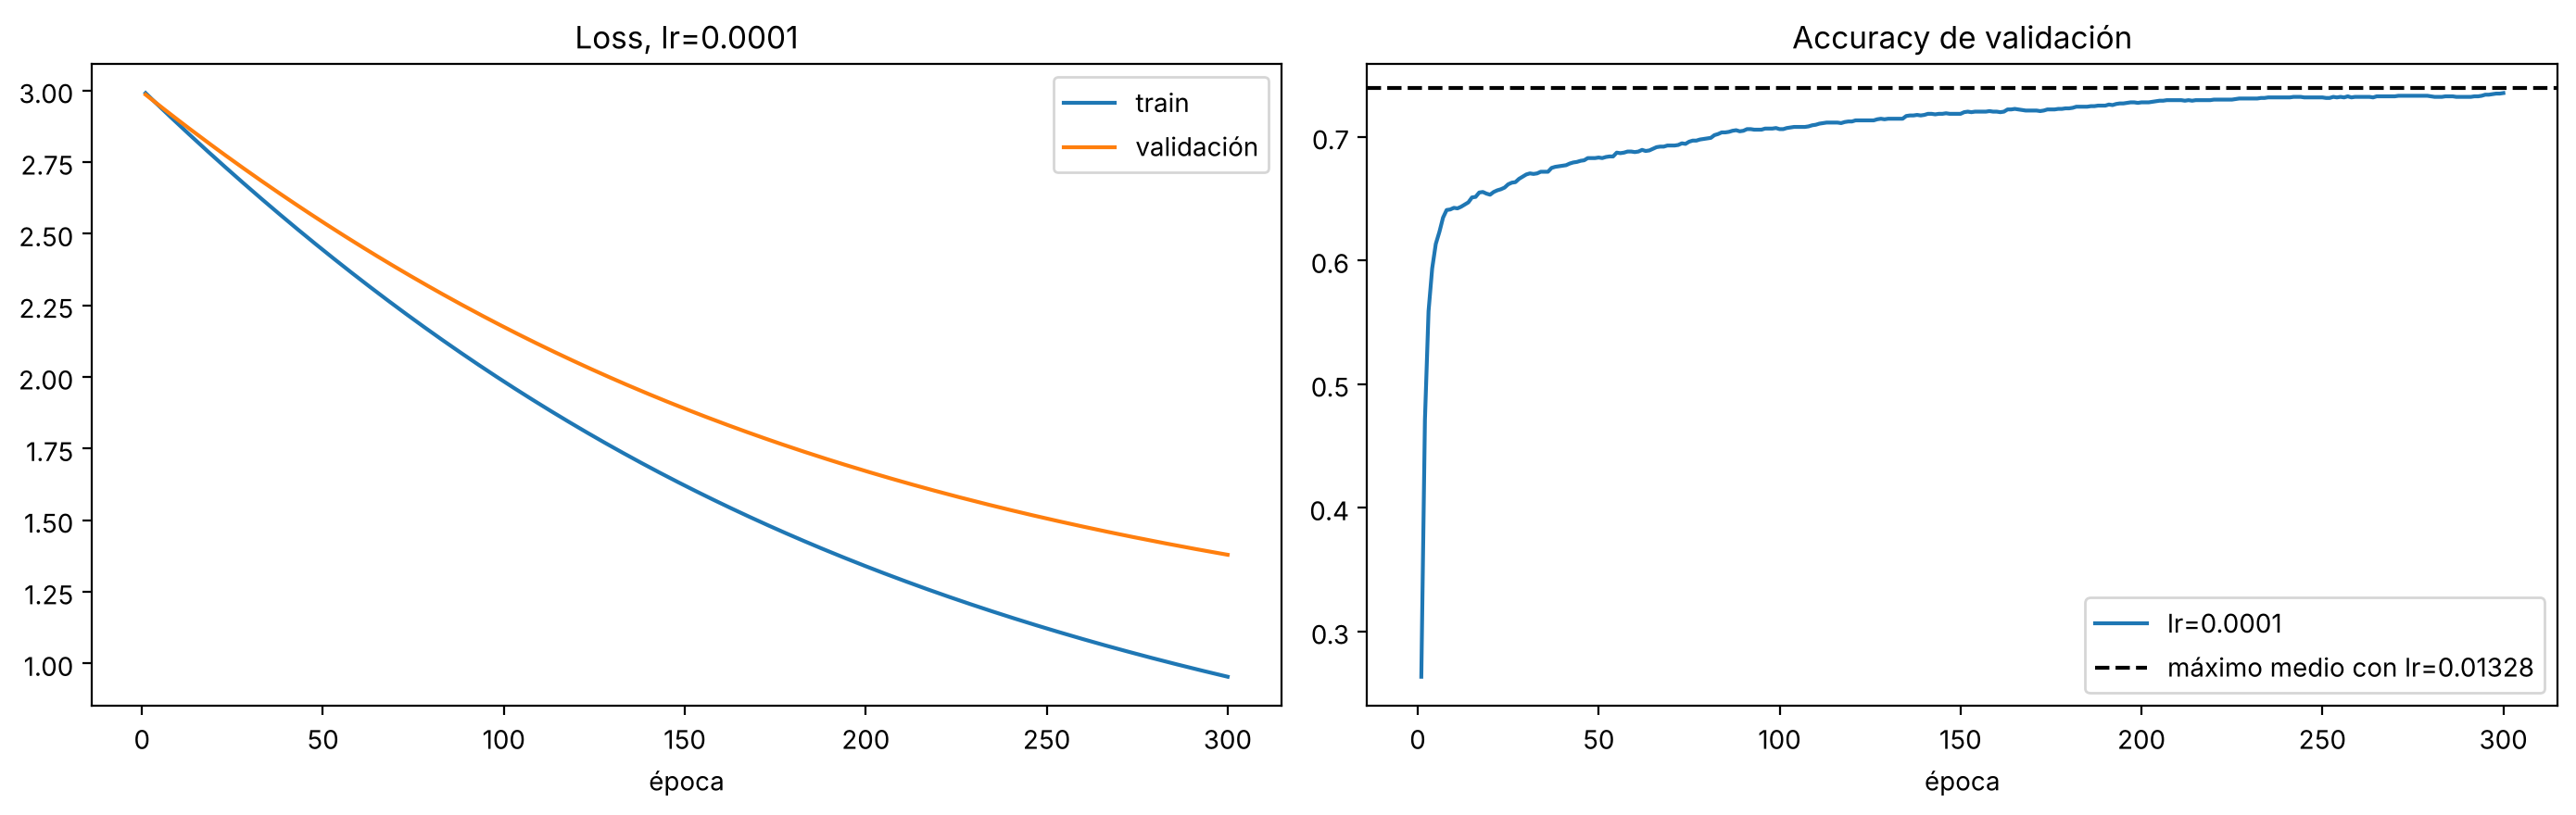

lr=0.0001: máximo val_acc = 0.7353 en la época 300, 99% del máximo en la época 203 (50.3s)
lr=0.01328: máximo val_acc medio = 0.7397, 99% del máximo en 0.8s en promedio


In [28]:
EPOCHS_LONG = 300
lr_small = learning_rates_to_test[0]
hist_long, _ = run_config(**{**BEST_CFG, "lr": lr_small}, epochs=EPOCHS_LONG, seeds=[SEED],
                          tag=f"softmax_lr_{lr_small:.4g}_long".replace(".", "_"), experiment_type="lr_long")
s_long = summarize_history(hist_long[0])
best_lr_peak = np.mean([summarize_history(h)["peak_val_acc"] for h in lr_histories[f"lr={BEST_LR:.4g}"]])
best_lr_time = np.mean([summarize_history(h)["time_to_99_s"] for h in lr_histories[f"lr={BEST_LR:.4g}"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(1, EPOCHS_LONG + 1), hist_long[0]["train_loss"], label="train")
axes[0].plot(range(1, EPOCHS_LONG + 1), hist_long[0]["val_loss"], label="validación")
axes[0].set_title(f"Loss, lr={lr_small:.4g}"); axes[0].legend()
axes[1].plot(range(1, EPOCHS_LONG + 1), hist_long[0]["val_acc"], label=f"lr={lr_small:.4g}")
axes[1].axhline(best_lr_peak, color="k", ls="--", label=f"máximo medio con lr={BEST_LR:.4g}")
axes[1].set_title("Accuracy de validación"); axes[1].legend()
for ax in axes:
    ax.set_xlabel("época")
plt.tight_layout(); plt.show()

print(f"lr={lr_small:.4g}: máximo val_acc = {s_long['peak_val_acc']:.4f} en la época {s_long['epoch_peak']}, "
      f"99% del máximo en la época {s_long['epoch_99']} ({s_long['time_to_99_s']:.1f}s)")
print(f"lr={BEST_LR:.4g}: máximo val_acc medio = {best_lr_peak:.4f}, 99% del máximo en {best_lr_time:.1f}s en promedio")

**Efecto del learning rate** (sobre validación, media ± desvío de 3 semillas)

* **El tiempo por época no depende del `lr`** (~0.25 s en todos los casos): cada paso hace las mismas operaciones. Lo que cambia es **cuántas épocas** hacen falta, y por lo tanto el tiempo hasta converger.
* **`lr` = 0.1:** es el que más rápido llega a su máximo (época ~2, menos de medio segundo), pero ese máximo es menor (0.726) y después la validación cae a 0.703 en la época 30. Los pasos son tan grandes que el modelo sobreajusta enseguida.
* **`lr` de Optuna (0.0133):** llega al 99% de su máximo en la época 3 (0.8 s), con el mejor máximo (0.740), y después baja lentamente por sobreajuste.
* **`lr` = 1e-3 y 1e-4:** a las 30 épocas todavía están subiendo (el máximo está en la última época). Con 1e-3 ya llega a 0.736, prácticamente lo mismo que el mejor; con 1e-4 está en 0.668.
* **La corrida larga separa "peor" de "más lento".** Con `lr` = 1e-4 durante 300 épocas, la validación llega a 0.735 y todavía sigue subiendo levemente en la época 300; alcanza el 99% de ese valor recién en la época ~200 (~50 s, contra ~0.8 s del `lr` de Optuna: unas 60 veces más). Es decir, **un `lr` chico no lleva a un modelo peor, sino a una convergencia mucho más lenta.**

Esto corrige lo que había escrito antes: que "con lr=0.1 se logra mejor accuracy que con lr=0.0001" era un efecto de cortar las dos corridas en la misma cantidad de épocas, no una diferencia en el modelo al que llegan. Además, aquella comparación estaba hecha sobre el test; ahora se hace sobre validación.

## 8.2. Análisis: efecto de `remove_stopwords` y `normalization`

Se compara el rendimiento de las 6 combinaciones de `remove_stopwords` y `normalization`, dejando el resto de los hiperparámetros como los de Optuna. Igual que antes, sobre **validación** y con 3 semillas por combinación, para poder ver si las diferencias son mayores que la variación entre semillas.

stopwords=mantenidas, none listo


stopwords=mantenidas, stem listo


stopwords=mantenidas, lemmatize listo


stopwords=quitadas, none listo


stopwords=quitadas, stem listo


stopwords=quitadas, lemmatize listo


,config,n_seeds,vocab_size,peak_val_acc,final_val_acc,epoch_peak,epoch_99,time_per_epoch_s,time_to_99_s
0,"stopwords=mantenidas, none",3,10000,0.7204 ± 0.0016,0.7058 ± 0.0002,6.00 ± 0.00,2.67 ± 0.47,0.26 ± 0.01,0.78 ± 0.07
1,"stopwords=mantenidas, stem",3,10000,0.7360 ± 0.0004,0.7210 ± 0.0009,7.33 ± 2.49,3.33 ± 0.47,0.28 ± 0.01,0.94 ± 0.16
2,"stopwords=mantenidas, lemmatize",3,10000,0.7254 ± 0.0015,0.7144 ± 0.0017,5.67 ± 1.25,3.00 ± 0.00,0.25 ± 0.00,0.76 ± 0.04
3,"stopwords=quitadas, none",3,10000,0.7266 ± 0.0019,0.7060 ± 0.0008,3.33 ± 0.47,2.00 ± 0.00,0.24 ± 0.00,0.53 ± 0.05
4,"stopwords=quitadas, stem",3,10000,0.7397 ± 0.0018,0.7276 ± 0.0002,6.00 ± 1.41,3.00 ± 0.00,0.25 ± 0.01,0.81 ± 0.09
5,"stopwords=quitadas, lemmatize",3,10000,0.7294 ± 0.0010,0.7107 ± 0.0009,4.33 ± 1.89,2.67 ± 0.47,0.25 ± 0.01,0.70 ± 0.15


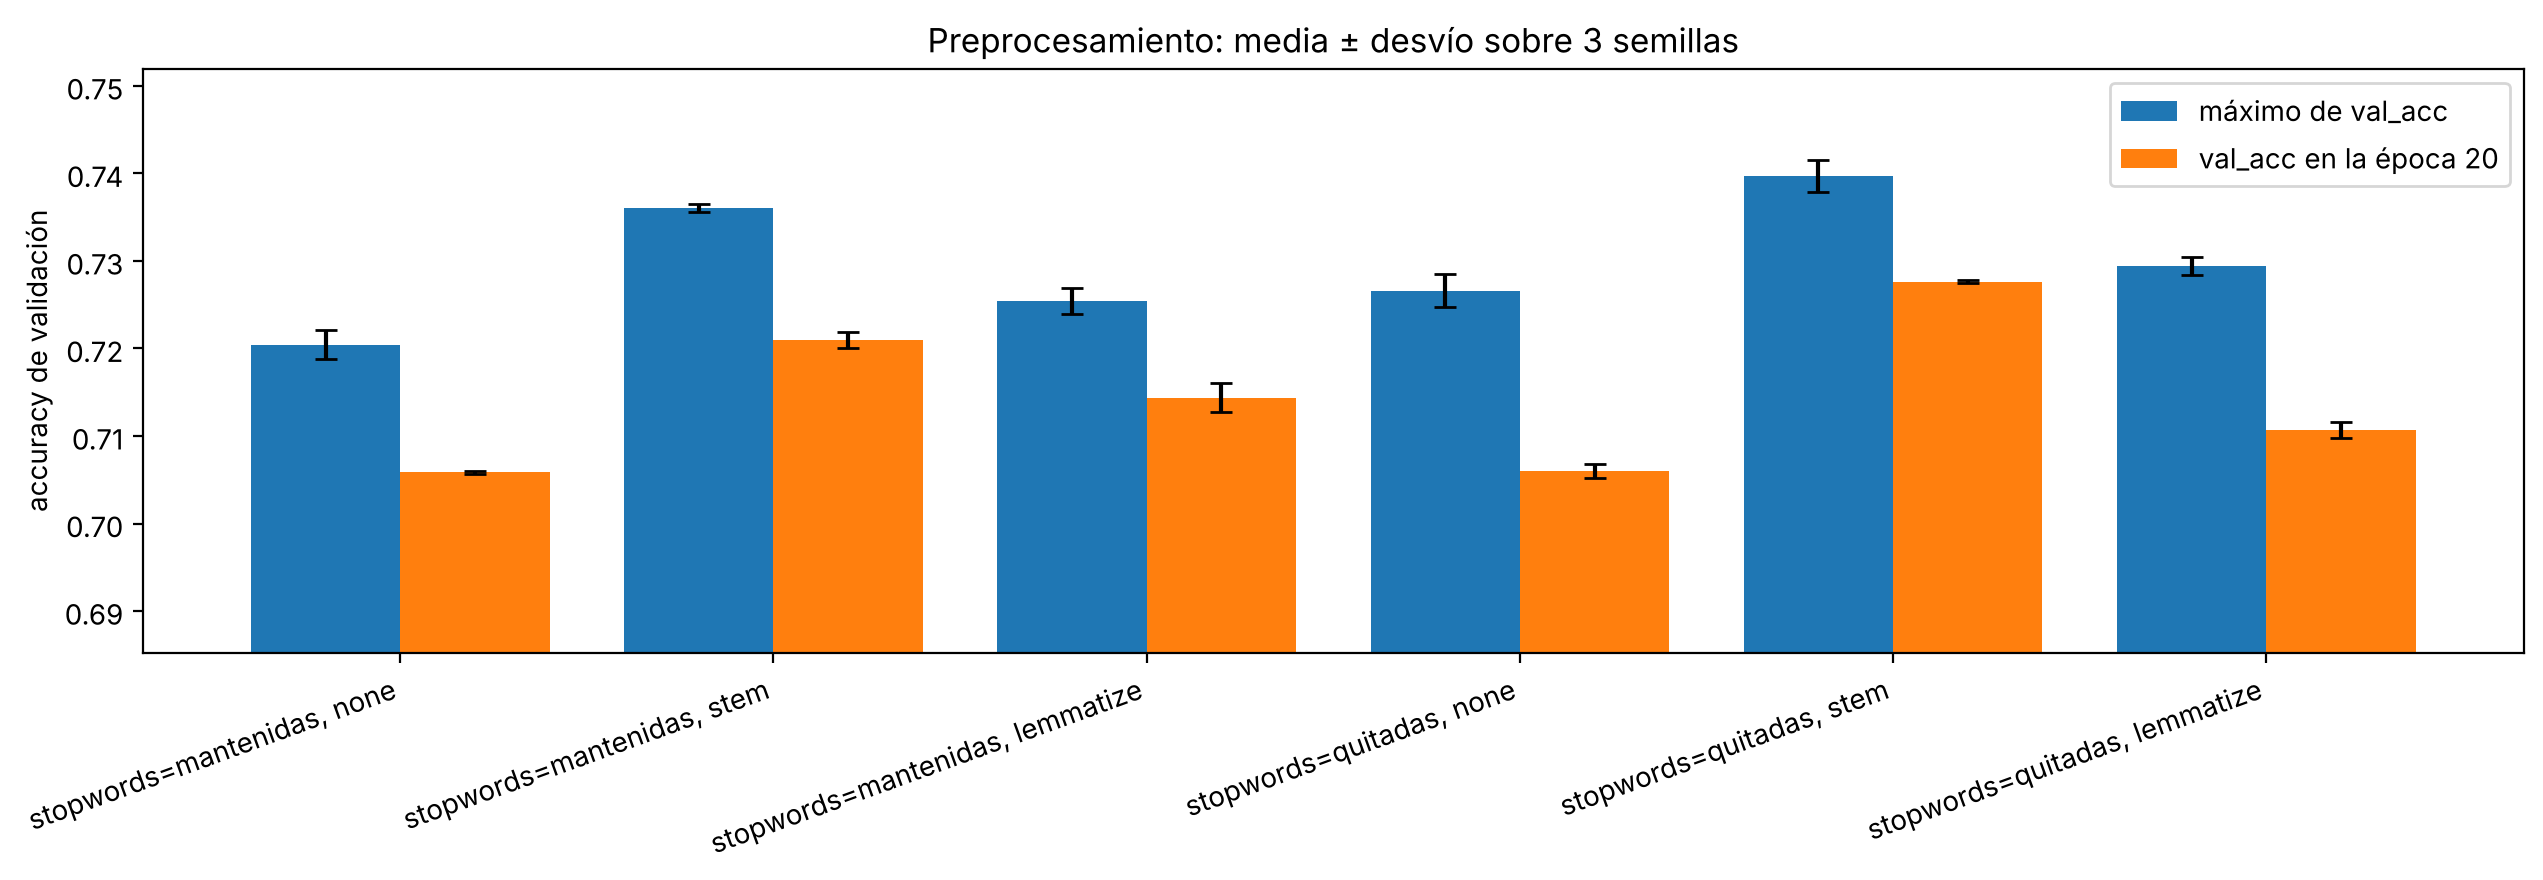

In [29]:
EPOCHS_PP = 20
preprocessing_combinations = [(rm, norm) for rm in [False, True] for norm in ["none", "stem", "lemmatize"]]

pp_histories, pp_vocab = {}, {}
for rm_sw, norm_pp in preprocessing_combinations:
    label = f"stopwords={'quitadas' if rm_sw else 'mantenidas'}, {norm_pp}"
    cfg = {**BEST_CFG, "remove_stopwords": rm_sw, "normalization": norm_pp}
    pp_histories[label], pp_vocab[label] = run_config(
        **cfg, epochs=EPOCHS_PP, seeds=SEEDS, tag=f"softmax_pp_rs_{str(rm_sw).lower()}_norm_{norm_pp}",
        experiment_type="preprocessing_variation")
    print(label, "listo")

pp_table = summary_table(pp_histories)
pp_table.insert(2, "vocab_size", [pp_vocab[c] for c in pp_table["config"]])
display(pp_table)

peaks = {k: [summarize_history(h)["peak_val_acc"] for h in hs] for k, hs in pp_histories.items()}
at_final = {k: [h["val_acc"][EPOCHS_FINAL - 1] for h in hs] for k, hs in pp_histories.items()}
labels = list(peaks)
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(x - 0.2, [np.mean(peaks[k]) for k in labels], 0.4, yerr=[np.std(peaks[k]) for k in labels],
       capsize=4, label="máximo de val_acc")
ax.bar(x + 0.2, [np.mean(at_final[k]) for k in labels], 0.4, yerr=[np.std(at_final[k]) for k in labels],
       capsize=4, label=f"val_acc en la época {EPOCHS_FINAL}")
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=20, ha="right")
lo = min(min(v) for v in at_final.values())
ax.set_ylim(lo - 0.02, max(max(v) for v in peaks.values()) + 0.01)
ax.set_ylabel("accuracy de validación"); ax.legend(); ax.set_title("Preprocesamiento: media ± desvío sobre 3 semillas")
plt.tight_layout(); plt.show()

**Efecto de `remove_stopwords` y `normalization`** (sobre validación, media ± desvío de 3 semillas)

* **`stem` es la mejor normalización en los dos casos**: 0.740 con stopwords quitadas y 0.736 sin quitarlas, contra 0.720-0.727 sin normalizar. El stemming junta variantes de una misma palabra (`run`, `running`, `runs`) en un solo término, lo que da más ocurrencias por feature. Con un vocabulario limitado a 10000 términos, además, entran más conceptos distintos. La lematización queda en el medio: `WordNetLemmatizer` sin etiqueta gramatical trata todo como sustantivo, así que unifica plurales pero no formas verbales (en el ejemplo de la sección 2, `studying` y `running` quedan iguales), y por eso junta menos variantes que el stemming.
* **Quitar stopwords ayuda poco**: entre 0.4 y 0.6 puntos según la normalización. Tiene sentido que el efecto sea chico: el IDF ya les da un peso muy bajo a las palabras que aparecen en casi todos los documentos, y las ~180 stopwords de NLTK ocupan una fracción mínima de los 10000 lugares del vocabulario. Además, algunas stopwords sí aportan información de estilo (por ejemplo, pronombres como `i`, `you`, `we` en las discusiones de religión o política). Esto explica que una de las corridas de Optuna de la versión anterior eligiera `remove_stopwords=False` pese a lo que esperaba: con diferencias de este tamaño, cuál gana en un trial puntual depende mucho del ruido.
* **¿Las diferencias son reales?** El desvío entre semillas es de ≤ 0.002, así que las diferencias son consistentes al cambiar la inicialización. Pero esa variabilidad no incluye la del split de validación. Como referencia, el error estándar de una accuracy de ~0.74 medida sobre 2263 documentos es ≈ √(0.74·0.26/2263) ≈ 0.009. Como todas las configuraciones se comparan sobre el mismo set de validación, la diferencia entre dos de ellas tiene menos varianza que eso, pero las diferencias de pocas décimas de punto (por ejemplo, entre `lemmatize` y `none` con stopwords quitadas) no deberían leerse como un ranking firme. La que sí es más robusta es la ventaja de `stem` sobre `none` (~1.3-1.6 puntos, en los dos casos).
* **Tiempos:** el tiempo por época es el mismo en todas las combinaciones (~0.25 s), porque el vocabulario queda en 10000 términos en todas. La diferencia de costo está en el preprocesamiento (la lematización es la más lenta), que se hace una sola vez en el cache y no entra en el tiempo por época.
* En esta versión, la mejor combinación de Optuna (stopwords quitadas + stem) coincide con la mejor de este análisis controlado. En la versión anterior no coincidían, lo que es coherente con que las diferencias sean chicas.

# 9. Preguntas de reflexión

#**Sobre Regresión Softmax (teoría)**
1. ¿Por qué la regresión softmax es una generalización de la regresión logística binaria? ¿Qué pasaría si `NUM_CLASSES = 2`?

La regresión Softmax puede manejar cualquier número de clases, mientras que la logística binaria está limitada a dos. Cuando NUM_CLASSES es 2, la regresión Softmax se reduce matemáticamente a la regresión logística binaria

2. ¿Por qué `CrossEntropyLoss` en PyTorch no necesita que se le aplique `softmax` antes en el forward? ¿Qué pasaría si igual lo aplicaran (softmax + CrossEntropyLoss)?

CrossEntropyLoss aplica internamente una función LogSoftmax a los logits de entrada y calcula la Negative Log Likelihood Loss (NLLLoss) a partir de las probabilidades logarítmicas resultantes y las labels. Si se aplicara softmax + CrossEntropyLoss:

  * La loss calculada sería errónea, ya que las probabilidades ya habrían sido escaladas por el primer softmax, y el segundo LogSoftmax las interpretaría incorrectamente.
  * Aumentaría la posibilidad de inestabilidad numérica que CrossEntropyLoss justamente busca evitar.

3. ¿Qué tipo de frontera de decisión puede aprender un modelo de regresión softmax? ¿Qué limitación tiene frente a un problema que no es linealmente separable?

Un modelo de regresión softmax puede aprender una frontera de decisión lineal entre múltiples clases.
No puede resolver problemas que no son linealmente separables porque se base en combinar las entradas de forma lineal antes de aplicar la función. Si las clases se tienen que dividir de una forma no lineal, el modelo va a fallar.


4. ¿En qué se diferencia este modelo de una red neuronal con capas ocultas? ¿En qué situación elegirían una sobre la otra?

Un modelo de una red con capas ocultas procesa la información en etapas intermedias para extraer relaciones no lineales.
Si el problema es lineal, sencillo, con pocos datos de entrenamiento o se necesita maximizar la interpretabilidad (que se vea el peso exacto de cada variable de entrada sobre el resultado final), usaría un modelo de capa simple. En cambio, si la cantidad de datos es muy grande, el problema es más complejo o importa más predecir mejor que explicar exactamente, elegiría el de capas ocultas.


#**Sobre frameworks y herramientas**

5. ¿Qué ventajas y desventajas tiene implementar esto en PyTorch (como hicimos) comparado con usar directamente `sklearn.linear_model.LogisticRegression(multi_class="multinomial")`?

Como ventaja, podemos controlar cada características del modelo como la función de loss, el optimizador y la forma en que se manejan los datos. Además, nos da la posibilidad de utilizar una red de capas ocultas si es que fuéramos a complejizar la clasificación.
Como desventaja, definir el modelo en PyTorch lleva más código y es más complejo que scikit-learn.


6. ¿Para qué sirvió específicamente MLflow en este TP? ¿En qué se diferencia de lo que loguea TensorBoard?

En este TP, se usó para guardar los mejores hiperparámetros, registrar las losses y los acurracies y guardar el modelo entrenado. Esto último permite cargarlo y reutilizarlo en el futuro.
TensorBoard permite visualizar las curvas de loss y accuracy para el entrenamiento y validación de todos los ensayos. Se pueden comparar runs específicas y permite ver si hay overfitting, fluctuaciones.



7. ¿Qué ventaja concreta les dio Optuna frente a probar combinaciones de hiperparámetros a mano?

Nos ahorró tener que decidir a mano qué combinaciones probar, y dejó registrados todos los trials para poder analizarlos después (sección 6.1). Optuna **no** prueba todas las combinaciones posibles: solo los hiperparámetros discretos ya dan 2 × 3 × 2 × 3 × 3 × 3 × 2 = 648 combinaciones, cada una con un `lr` continuo, y se corrieron 30 trials. Lo que hace es explorar el espacio de forma **guiada y no exhaustiva**: los primeros trials del sampler TPE son aleatorios, y después modela qué valores dieron mejores resultados y propone combinaciones cerca de esos. Se ve en la historia de la búsqueda: a partir del trial ~22 casi todos los trials repiten la configuración ganadora y solo varían el `lr`. Frente a un grid search, llega a buenas configuraciones con muchos menos ensayos. La contracara es que no garantiza encontrar el óptimo y que, con pocos trials, la configuración "ganadora" depende bastante de la semilla.


8. ¿Qué combinación de preprocesamiento (stopwords, stemming/lematización, n-gramas) encontró Optuna como mejor? ¿Tiene sentido para este dataset?

En la corrida que quedó en el notebook (30 trials, sampler con semilla), la mejor configuración fue:

        remove_stopwords=True, normalization='stem', ngram_range='1gram', max_features=10000, min_df=1,
        optimizer='Adam', lr=0.0133, batch_size=128  →  accuracy de validación 0.7402

* **Stopwords quitadas:** tiene sentido porque son palabras que no distinguen temas. Igual, el efecto es chico (0.4-0.6 puntos en 8.2), porque el IDF ya les da poco peso.
* **Stemming:** fue la mejor normalización tanto en Optuna como en el análisis controlado de 8.2. Junta las variantes de cada palabra y, con el vocabulario limitado, deja lugar para más términos distintos. La lematización sin etiqueta gramatical junta menos variantes.
* **Solo unigramas:** con `max_features=10000`, los bigramas le sacan lugar a unigramas informativos; los 4 trials con bigramas rindieron peor en promedio. Para tener una conclusión firme sobre bigramas habría que probarlos con un vocabulario más grande.
* **`max_features=10000`** (el máximo del rango) fue lo más importante: con 2000 términos se pierde mucha información. **`min_df=1`** no mostró una diferencia clara con 2 o 5: con el vocabulario recortado a los 10000 términos más frecuentes, los términos que aparecen en un solo documento casi nunca entran igual.
* **Adam** superó a SGD. Una vez que SGD tuvo su propio rango de `lr`, la diferencia se redujo (0.70 contra 0.74), pero sigue a favor de Adam con 5 épocas.
* **Ya no aparece `norm_type`:** como se mostró en la sección 3, las dos opciones eran idénticas.

En la versión anterior, dos corridas de Optuna (15 trials, sin semilla) habían dado configuraciones muy distintas (stopwords sí/no, unigramas o bigramas, `min_df` 1 o 2). Más que una contradicción, eso muestra que con pocos trials hay varias configuraciones a menos de un punto de distancia, y cuál sale "mejor" depende del ruido de la búsqueda. Lo que se mantuvo en todas las corridas es lo que más pesa: stemming, vocabulario de 10000 términos y Adam con un `lr` del orden de 0.01.


9. ¿En qué categorías del dataset se confunde más el modelo (según la matriz de confusión)? ¿Por qué creen que pasa (piensen en el contenido temático de esas categorías)?

        1. Real: 'talk.politics.misc'       - Predicha como: 'talk.politics.guns'       (76)
        2. Real: 'talk.religion.misc'       - Predicha como: 'soc.religion.christian'   (55)
        3. Real: 'comp.windows.x'           - Predicha como: 'comp.graphics'            (47)
        4. Real: 'rec.motorcycles'          - Predicha como: 'rec.autos'                (43)
        5. Real: 'alt.atheism'              - Predicha como: 'soc.religion.christian'   (41)
        6. Real: 'comp.sys.ibm.pc.hardware' - Predicha como: 'comp.os.ms-windows.misc'  (41)
        7. Real: 'comp.sys.mac.hardware'    - Predicha como: 'comp.sys.ibm.pc.hardware' (41)

Las que más se confunden son categorías del mismo grupo temático: política, religión, computación y vehículos. Comparten gran parte del vocabulario (por ejemplo, `god`, `bible` y `belief` aparecen en las tres de religión, y `windows`, `drive` y `card` en las de computación), y un modelo lineal sobre TF-IDF solo puede separarlas por la presencia de palabras sueltas. Las categorías "misc" (`talk.politics.misc`, `talk.religion.misc`) son las peores porque, por definición, mezclan temas de sus categorías hermanas, y además son las que tienen menos ejemplos.


10. ¿Cambiaría su respuesta a la pregunta anterior si usaran un modelo con capas ocultas en vez de regresión softmax? ¿Por qué sí o por qué no?

Si se usara un modelo con capas ocultas, se podría reducir la confusión entre las categorías que están más relacionadas. Pero aún así, si hay confusiones de este tipo, la razón seguiría siendo la misma.